# HiENBERT — Reviewer-Response Study (SHAP-guided refinement + α₃ analysis)

Self-contained notebook. It re-creates your data pipeline (`Common_Dataset/{train,dev,test}.csv`), so it does **not** depend on kernel state from the original notebook.

| Reviewer comment | Where addressed |
|---|---|
| R1-4 "α₃=0.5 only empirical, no theory, no sensitivity analysis" | **Part A**: multi-seed sweep, per-task Macro-F1, Pareto view, gradient-balance + uncertainty-weighting justification, significance tests |
| R1-5, R2-5 "SHAP only post-hoc, never fed back to improve the model" | **Part B**: attribution → mine shortcut/misleading tokens → augment → fine-tune → re-measure, with random-masking and plain-continue **controls** |
| R1-7 "use ontology / keyword constraints for Waste vs Health confusion" | **Part B** (attribution-mined lexicon + optional manual ontology, β tuned on dev) |
| R1-3, R2-1 "Hinglish failure modes, error statistics, remedies" | **Part C** (fragmentation / code-mix / confusion statistics + language-view-dropout remedy) |
| R2-2 "multi-task gain is only 1.1–1.7 %" | **Part A** also retrains true single-task models  — multi-seed, same recipe |

**Protocol rules baked in (so reviewers can't attack the study):**
* Model selection and α₃ selection use **dev only**; test is touched once per run.
* Dev is split 50/50 into `dev_mine` (mine tokens from errors) and `dev_sel` (early stopping / acceptance) so mining never leaks into selection.
* Every XAI-guided arm has a matched **random-masking** control and a **plain continue-training** control with identical extra epochs.
* Everything is resumable: each run writes a JSON in `reviewer_study/runs/`; re-running a cell skips finished runs.

**Run order (important):** setup → data → model → **Part B** (one reference model, then SHAP results appear within the first ~15–30 min, then refinement, lexicon) → **Part A** (the α₃ sweep: the long part, safe to interrupt; finished runs are reused) → **Part C** → report. Part A is deliberately last so you never wait for it to see SHAP.

**Hugging Face token:** edit `HF_TOKEN` in the first code cell (a dummy is fine for public `xlm-roberta-base`).

**Profiles** — set `HIENBERT_PROFILE` (env var) or edit `CFG.PROFILE` in cell 1: `smoke` (minutes, sanity check), `quick` (**default**: 1 seed, 3 epochs, 3 α₃ values), `fast` (2 seeds, 5 α₃ values, 5 epochs), `full` (3 seeds × 8 α₃ values).


In [1]:
# ============================================================================
# SETUP & CONFIG
# ============================================================================
import os, sys, json, time, copy, math, random, re, gc, string, pickle, warnings
warnings.filterwarnings("ignore")
from collections import Counter, defaultdict
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from tqdm.auto import tqdm

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import AutoTokenizer, AutoModel, get_cosine_schedule_with_warmup
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# ---- Hugging Face token: paste yours here (a dummy is fine for public models like xlm-roberta-base; it only raises rate limits) ----
HF_TOKEN = "hf_REPLACE_WITH_YOUR_TOKEN"
if HF_TOKEN and "REPLACE" not in HF_TOKEN:
    os.environ["HF_TOKEN"] = HF_TOKEN; os.environ["HUGGING_FACE_HUB_TOKEN"] = HF_TOKEN
import transformers; transformers.logging.set_verbosity_error()      # silences the "LOAD REPORT" spam on every model build

# Windows fix: default text encoding is cp1252 there, which cannot write Hindi. Force UTF-8 for every text-mode open() in this notebook.
import builtins
_builtin_open = builtins.open
def open(file, mode='r', *a, **k):
    if 'b' not in mode and 'encoding' not in k: k['encoding'] = 'utf-8'
    return _builtin_open(file, mode, *a, **k)

PROFILES = {
    # quick (DEFAULT): ~1 reference model + SHAP analysis + 2 refinement rounds + a 3-point alpha3 sweep, 1 seed
    "quick": dict(ALPHAS=[0.25, 0.5, 1.0], SEEDS=[11], EPOCHS=3, N_TRAIN=None, N_EVAL=None,
                  TRAIN_ATTR_N=1500, DEV_MINE_N=800, AUG_MAX=3000, ROUNDS=2, REFINE_EPOCHS=1,
                  SHAP_N=30, FAITH_N=300, RUN_SINGLE_TASK=False, RUN_UNCERTAINTY=False),
    # smoke: verify the pipeline end-to-end on tiny subsets (minutes)
    "smoke": dict(ALPHAS=[0.0, 0.5, 1.0], SEEDS=[11], EPOCHS=1, N_TRAIN=256, N_EVAL=160,
                  TRAIN_ATTR_N=48, DEV_MINE_N=64, AUG_MAX=64, ROUNDS=1, REFINE_EPOCHS=1,
                  SHAP_N=6, FAITH_N=24, RUN_SINGLE_TASK=True, RUN_UNCERTAINTY=True),
    # fast: ~5 alphas x 2 seeds (hours)
    "fast":  dict(ALPHAS=[0.0, 0.25, 0.5, 1.0, 2.0], SEEDS=[11, 22], EPOCHS=5, N_TRAIN=None, N_EVAL=None,
                  TRAIN_ATTR_N=2500, DEV_MINE_N=1500, AUG_MAX=4000, ROUNDS=2, REFINE_EPOCHS=2,
                  SHAP_N=40, FAITH_N=500, RUN_SINGLE_TASK=True, RUN_UNCERTAINTY=True),
    # full: paper-grade
    "full":  dict(ALPHAS=[0.0, 0.1, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0], SEEDS=[11, 22, 33], EPOCHS=6, N_TRAIN=None, N_EVAL=None,
                  TRAIN_ATTR_N=4000, DEV_MINE_N=1500, AUG_MAX=6000, ROUNDS=3, REFINE_EPOCHS=2,
                  SHAP_N=60, FAITH_N=800, RUN_SINGLE_TASK=True, RUN_UNCERTAINTY=True),
}

class CFG:
    PROFILE = os.environ.get("HIENBERT_PROFILE", "quick")
    # ---- paths: same layout as your original notebook ----
    PROJECT_DIR = os.getcwd()
    DATA_DIR    = os.path.join(PROJECT_DIR, "Common_Dataset")
    OUT_DIR     = os.path.join(PROJECT_DIR, "hienbert_results_CommonDataset", "reviewer_study")
    # optional: reuse the model you already trained (used as the refinement starting point if present)
    EXISTING_CKPT = os.path.join(PROJECT_DIR, "hienbert_results_CommonDataset", "models", "best_hienbert_model.pt")
    # ---- model / optimisation (matches your original recipe) ----
    MODEL_NAME = "xlm-roberta-base"      # public model, no HF token needed
    MAX_LENGTH, BATCH, LR, DROPOUT, WD, WARMUP, PATIENCE = 128, 32, 2e-5, 0.3, 0.01, 0.1, 2
    LOSS = "ce"          # "ce" = what your notebook actually trained with; "focal" = what the paper text describes (Eq. 10)
    FOCAL_ALPHA, FOCAL_GAMMA = 0.25, 2.0
    MAIN_SEED_DEFAULT = 11
    LOOP_ATTR = 'occlusion'   # attribution used INSIDE the refinement loop: 'occlusion' (fast) or 'shapley' (permutation-sampled SHAP, ~4x slower)
    REF_ALPHA = 0.5      # alpha3 of the reference model used by Part B (paper value). Change after Part A if the dev-selected alpha3* differs.
    # ---- test hooks (leave None in real runs) ----
    BACKBONE_FN = None
    TOKENIZER_FN = None

P = PROFILES[CFG.PROFILE]
for k, v in P.items(): setattr(CFG, k, v)
CFG.REFINE_SEEDS = CFG.SEEDS[:1]          # extend to CFG.SEEDS for multi-seed refinement (costly)

DEVICE  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
for sub in ["runs", "preds", "ckpt", "figs", "tables", "xai"]:
    os.makedirs(os.path.join(CFG.OUT_DIR, sub), exist_ok=True)
def OUT(*p): return os.path.join(CFG.OUT_DIR, *p)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

print(f"profile={CFG.PROFILE}  device={DEVICE}  amp={USE_AMP}  loss={CFG.LOSS}")
print(f"alphas={CFG.ALPHAS}  seeds={CFG.SEEDS}  epochs={CFG.EPOCHS}")
print("outputs ->", CFG.OUT_DIR)


profile=quick  device=cuda  amp=True  loss=ce
alphas=[0.25, 0.5, 1.0]  seeds=[11]  epochs=3
outputs -> C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\reviewer_study


In [2]:
# ============================================================================
# DATA (same preprocessing as your original notebook) + splits
# ============================================================================
COLMAP = {'primary_category': 'category_primary', 'secondary_category': 'category_secondary',
          'Severity': 'severity', 'Complaint_Title': 'complaint_title', 'Text_en': 'text_en',
          'Text_hi': 'Hindi', 'Text_hinglish': 'Hinglish'}
TEXT_COLS = ['complaint_title', 'text_en', 'Hindi', 'Hinglish']
VIEWS = {'concat': 'text', 'english': 'text_en', 'hindi': 'Hindi', 'hinglish': 'Hinglish'}
TASKS = ['primary', 'subcat', 'severity']

def load_split(path):
    df = pd.read_csv(path)
    df = df.rename(columns={k: v for k, v in COLMAP.items() if k in df.columns})
    for c in TEXT_COLS:
        df[c] = df[c].fillna('').astype(str) if c in df.columns else ''
    df['text'] = df[TEXT_COLS].agg(' '.join, axis=1).str.replace(r'\s+', ' ', regex=True).str.strip()
    df = df.dropna(subset=['category_primary', 'category_secondary', 'severity'])
    return df.reset_index(drop=True)

train_df = load_split(os.path.join(CFG.DATA_DIR, 'train.csv'))
dev_df   = load_split(os.path.join(CFG.DATA_DIR, 'dev.csv'))
test_df  = load_split(os.path.join(CFG.DATA_DIR, 'test.csv'))

le_p, le_s, le_v = LabelEncoder(), LabelEncoder(), LabelEncoder()
le_p.fit(train_df['category_primary']); le_s.fit(train_df['category_secondary']); le_v.fit(train_df['severity'])
for d in (train_df, dev_df, test_df):
    d['primary_label']  = le_p.transform(d['category_primary'])
    d['subcat_label']   = le_s.transform(d['category_secondary'])
    d['severity_label'] = le_v.transform(d['severity'])
    d['is_aug'] = 0
N_CLS = {'primary': len(le_p.classes_), 'subcat': len(le_s.classes_), 'severity': len(le_v.classes_)}
CLASS_NAMES = {'primary': list(le_p.classes_), 'subcat': list(le_s.classes_), 'severity': list(le_v.classes_)}

if CFG.N_TRAIN:   # smoke profile only
    train_df = train_df.sample(min(CFG.N_TRAIN, len(train_df)), random_state=0).reset_index(drop=True)
    dev_df   = dev_df.sample(min(CFG.N_EVAL, len(dev_df)), random_state=0).reset_index(drop=True)
    test_df  = test_df.sample(min(CFG.N_EVAL, len(test_df)), random_state=0).reset_index(drop=True)

# dev is split in two so that mining tokens from errors never leaks into model selection
try:
    dev_mine, dev_sel = train_test_split(dev_df, test_size=0.5, stratify=dev_df['primary_label'], random_state=0)
except ValueError:
    dev_mine, dev_sel = train_test_split(dev_df, test_size=0.5, random_state=0)
dev_mine, dev_sel = dev_mine.reset_index(drop=True), dev_sel.reset_index(drop=True)

print({k: len(v) for k, v in dict(train=train_df, dev_mine=dev_mine, dev_sel=dev_sel, test=test_df).items()}, N_CLS)

if CFG.TOKENIZER_FN: tok = CFG.TOKENIZER_FN()
else:
    tok = AutoTokenizer.from_pretrained(CFG.MODEL_NAME, use_fast=True)
MASK = tok.mask_token or '[MASK]'

class ComplaintDS(Dataset):
    """Pre-tokenised dataset. view_dropout_p>0 => with that probability a row is replaced by ONE language view
    (English / Hindi / Hinglish) - the remedy tested for the Hinglish train/test mismatch (Part C).
    Rows flagged is_aug=1 (XAI-generated counterfactuals) are never view-swapped."""
    def __init__(self, df, tok, max_len=128, view_dropout_p=0.0, seed=0):
        self.df = df.reset_index(drop=True); self.p = view_dropout_p; self.rng = np.random.RandomState(seed)
        cols = ['text'] + (['text_en', 'Hindi', 'Hinglish'] if view_dropout_p > 0 else [])
        self.enc = {}
        for c in cols:
            e = tok(self.df[c].astype(str).tolist(), truncation=True, padding='max_length', max_length=max_len)
            self.enc[c] = (np.asarray(e['input_ids'], dtype=np.int64), np.asarray(e['attention_mask'], dtype=np.int64))
        self.y = {'primary': self.df['primary_label'].values.astype(np.int64),
                  'subcat': self.df['subcat_label'].values.astype(np.int64),
                  'severity': self.df['severity_label'].values.astype(np.int64)}
        self.aug = self.df['is_aug'].values.astype(bool)
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        c = 'text'
        if self.p > 0 and not self.aug[i] and self.rng.rand() < self.p:
            c = ['text_en', 'Hindi', 'Hinglish'][self.rng.randint(3)]
        ids, am = self.enc[c]
        if am[i].sum() <= 2: ids, am = self.enc['text']
        return {'input_ids': torch.from_numpy(ids[i]), 'attention_mask': torch.from_numpy(am[i]),
                'primary': torch.tensor(self.y['primary'][i]), 'subcat': torch.tensor(self.y['subcat'][i]),
                'severity': torch.tensor(self.y['severity'][i])}

def collate_trim(batch):
    out = {k: torch.stack([b[k] for b in batch]) for k in batch[0]}
    L = int(out['attention_mask'].sum(1).max())
    out['input_ids'], out['attention_mask'] = out['input_ids'][:, :L], out['attention_mask'][:, :L]
    return out

def make_loader(ds, bs, shuffle, seed=0):
    g = torch.Generator(); g.manual_seed(seed)
    return DataLoader(ds, batch_size=bs, shuffle=shuffle, num_workers=0, collate_fn=collate_trim, generator=g)


{'train': 14165, 'dev_mine': 1517, 'dev_sel': 1518, 'test': 3036} {'primary': 8, 'subcat': 24, 'severity': 3}


In [3]:
# ============================================================================
# MODEL, LOSSES, TRAINING, EVALUATION, GRADIENT DIAGNOSTICS
# ============================================================================
class HiENBERT(nn.Module):
    """Identical to your trained OptimizedHiEnBERT (so your existing checkpoint loads).
    Optional `log_vars` = learned task uncertainties (Kendall & Gal, 2018) for the uncertainty-weighting arm."""
    def __init__(self, backbone, n_p, n_s, n_v, dropout=0.3, uncertainty=False):
        super().__init__()
        self.base = backbone; h = backbone.config.hidden_size
        self.shared, self.gelu, self.dropout = nn.Linear(h, h), nn.GELU(), nn.Dropout(dropout)
        self.fc_primary, self.fc_subcat, self.fc_severity = nn.Linear(h, n_p), nn.Linear(h, n_s), nn.Linear(h, n_v)
        self.n_cls = {'primary': n_p, 'subcat': n_s, 'severity': n_v}
        self.log_vars = nn.Parameter(torch.zeros(3)) if uncertainty else None
        for m in (self.shared, self.fc_primary, self.fc_subcat, self.fc_severity):
            nn.init.xavier_uniform_(m.weight); nn.init.zeros_(m.bias)
    def encode(self, input_ids, attention_mask):
        return self.base(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state[:, 0, :]
    def heads(self, cls):
        x = self.dropout(self.gelu(self.shared(cls)))
        return self.fc_primary(x), self.fc_subcat(x), self.fc_severity(x)
    def forward(self, input_ids, attention_mask, sentiment=None):
        return self.heads(self.encode(input_ids, attention_mask))

_BB = {}
def build_model(uncertainty=False):
    if CFG.BACKBONE_FN: bb = CFG.BACKBONE_FN()
    else:      # download/load XLM-R once, then deep-copy for every new run (saves ~10-30 s per run)
        if 'bb' not in _BB: _BB['bb'] = AutoModel.from_pretrained(CFG.MODEL_NAME)
        bb = copy.deepcopy(_BB['bb'])
    return HiENBERT(bb, N_CLS['primary'], N_CLS['subcat'], N_CLS['severity'], CFG.DROPOUT, uncertainty).to(DEVICE)

def focal_loss(logits, y, gamma=2.0, alpha=0.25):
    logp = F.log_softmax(logits.float(), -1).gather(1, y[:, None]).squeeze(1)
    return (-alpha * (1 - logp.exp()) ** gamma * logp).mean()

def task_losses(logits3, ys, loss_type):
    f = (lambda l, y: F.cross_entropy(l.float(), y)) if loss_type == 'ce' else \
        (lambda l, y: focal_loss(l, y, CFG.FOCAL_GAMMA, CFG.FOCAL_ALPHA))
    return [f(l, y) for l, y in zip(logits3, ys)]

def combine(model, losses, alphas):
    if model.log_vars is not None:          # L = sum_i exp(-s_i) L_i + s_i,  s_i = log sigma_i^2
        s = model.log_vars
        return sum(torch.exp(-s[i]) * losses[i] + s[i] for i in range(3))
    return sum(a * l for a, l in zip(alphas, losses))

def metrics_from(preds, labels):
    m = {}
    for t in TASKS:
        if len(preds.get(t, [])) == 0: continue
        m[t] = dict(acc=float(accuracy_score(labels[t], preds[t])),
                    f1_macro=float(f1_score(labels[t], preds[t], average='macro', zero_division=0)),
                    f1_weighted=float(f1_score(labels[t], preds[t], average='weighted', zero_division=0)))
    if all(t in m for t in TASKS):
        m['mt_f1'] = float(np.mean([m[t]['f1_macro'] for t in TASKS]))
        m['mt_acc'] = float(np.mean([m[t]['acc'] for t in TASKS]))
    return m

@torch.no_grad()
def predict_all(model, loader):
    model.eval(); P = {t: [] for t in TASKS}; Y = {t: [] for t in TASKS}
    for b in loader:
        ids, am = b['input_ids'].to(DEVICE), b['attention_mask'].to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            out = model(ids, am)
        for t, o in zip(TASKS, out): P[t] += o.argmax(-1).cpu().tolist(); Y[t] += b[t].tolist()
    return {t: np.array(v) for t, v in P.items()}, {t: np.array(v) for t, v in Y.items()}

def eval_df(model, df, bs=64):
    return predict_all(model, make_loader(ComplaintDS(df, tok, CFG.MAX_LENGTH), bs, False))

def eval_views(model, df):
    """Macro-F1/acc of all three tasks when the model sees ONE language column at a time."""
    res = {}
    for name, col in VIEWS.items():
        d = df.copy(); d['text'] = d[col].astype(str)
        p, y = eval_df(model, d); res[name] = metrics_from(p, y)
    return res

def gradient_conflict(model, loader, n_batches=6, loss_type='ce'):
    """Gradient of each task loss w.r.t. the SHARED layer weight (the point where the tasks compete).
    Returns grad norms and pairwise cosines. cos<0 => tasks conflict. Encoder run under no_grad (cheap)."""
    model.eval(); W = model.shared.weight; recs = []
    for i, b in enumerate(loader):
        if i >= n_batches: break
        ids, am = b['input_ids'].to(DEVICE), b['attention_mask'].to(DEVICE)
        with torch.no_grad(): cls = model.encode(ids, am).float()
        ls = task_losses(model.heads(cls), [b[t].to(DEVICE) for t in TASKS], loss_type)
        g = [torch.autograd.grad(L, W, retain_graph=True)[0].flatten() for L in ls]
        cs = lambda a, c: F.cosine_similarity(a, c, dim=0).item()
        recs.append(dict(n_p=g[0].norm().item(), n_s=g[1].norm().item(), n_v=g[2].norm().item(),
                         cos_ps=cs(g[0], g[1]), cos_pv=cs(g[0], g[2]), cos_sv=cs(g[1], g[2])))
    return {k: float(np.mean([r[k] for r in recs])) for k in recs[0]}

def run_cached(tag, seed, save_ckpt=None, epochs=None):
    """A finished run is reused only if it was trained with the same number of epochs (prevents silently mixing profiles)."""
    f = OUT('runs', f'{tag}_s{seed}.json')
    if not os.path.exists(f): return False
    if epochs is not None and json.load(open(f)).get('epochs_cfg') != epochs: return False
    return save_ckpt is None or os.path.exists(save_ckpt)

def train_run(tag, seed, alphas, train_data, dev_data, test_data, *, epochs, lr=None, loss_type=None,
              uncertainty=False, view_dropout_p=0.0, init_state=None, save_ckpt=None, select_task=None,
              grad_diag=True, do_views=True, patience=None):
    """Train once, select the epoch on DEV only, report TEST once. Fully resumable via runs/<tag>_s<seed>.json."""
    rf = OUT('runs', f'{tag}_s{seed}.json')
    if run_cached(tag, seed, save_ckpt, epochs): return json.load(open(rf))
    lr = lr or CFG.LR; loss_type = loss_type or CFG.LOSS; patience = patience or CFG.PATIENCE
    set_seed(seed); t0 = time.time()
    model = build_model(uncertainty)
    if init_state is not None: model.load_state_dict(init_state, strict=False)
    tr_loader = make_loader(ComplaintDS(train_data, tok, CFG.MAX_LENGTH, view_dropout_p, seed), CFG.BATCH, True, seed)
    dv_loader = make_loader(ComplaintDS(dev_data, tok, CFG.MAX_LENGTH), 64, False)
    main = [p for n, p in model.named_parameters() if n != 'log_vars']
    groups = [dict(params=main, lr=lr, weight_decay=CFG.WD)]
    if uncertainty: groups.append(dict(params=[model.log_vars], lr=1e-2, weight_decay=0.0))
    opt = AdamW(groups); total = len(tr_loader) * epochs
    sched = get_cosine_schedule_with_warmup(opt, int(CFG.WARMUP * total), total)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    sel = (lambda m: m[select_task]['f1_macro']) if select_task else (lambda m: m['mt_f1'])
    best, best_state, best_ep, bad, hist = -1, None, -1, 0, []
    for ep in range(epochs):
        model.train(); tl = np.zeros(3); n = 0
        for b in tqdm(tr_loader, desc=f'{tag} s{seed} ep{ep+1}/{epochs}', leave=False):
            ids, am = b['input_ids'].to(DEVICE), b['attention_mask'].to(DEVICE)
            ys = [b[t].to(DEVICE) for t in TASKS]
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                out = model(ids, am)
            ls = task_losses(out, ys, loss_type); loss = combine(model, ls, alphas)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad(set_to_none=True)
            tl += np.array([l.item() for l in ls]); n += 1
        p, y = predict_all(model, dv_loader); dm = metrics_from(p, y)
        rec = dict(epoch=ep + 1, train_loss=(tl / max(n, 1)).tolist(), dev=dm)
        if grad_diag and not select_task: rec['grad'] = gradient_conflict(model, dv_loader, 6, loss_type)
        if model.log_vars is not None: rec['learned_w'] = torch.exp(-model.log_vars).detach().cpu().tolist()
        hist.append(rec); sc = sel(dm)
        print(f"  {tag} s{seed} ep{ep+1}: dev mt_f1={dm.get('mt_f1', float('nan')):.4f} "
              f"P={dm['primary']['f1_macro']:.4f} S={dm['subcat']['f1_macro']:.4f} V={dm['severity']['f1_macro']:.4f}")
        if sc > best + 1e-4:
            best, best_ep, bad = sc, ep + 1, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state)
    dp, dy = predict_all(model, dv_loader); tp, ty = eval_df(model, test_data)
    res = dict(epochs_cfg=epochs, tag=tag, seed=seed, alphas=list(alphas), uncertainty=uncertainty, loss=loss_type,
               view_dropout_p=view_dropout_p, best_epoch=best_ep, epochs_run=len(hist),
               dev=metrics_from(dp, dy), test=metrics_from(tp, ty), history=hist,
               train_time_s=time.time() - t0)
    if model.log_vars is not None: res['learned_w'] = torch.exp(-model.log_vars).detach().cpu().tolist()
    if do_views: res['views'] = eval_views(model, test_data)
    np.savez_compressed(OUT('preds', f'{tag}_s{seed}.npz'),
                        **{f'{t}_pred': tp[t] for t in TASKS}, **{f'{t}_true': ty[t] for t in TASKS})
    if save_ckpt: torch.save({'model_state_dict': best_state}, save_ckpt)
    json.dump(res, open(rf, 'w'), indent=1)
    del model, opt, best_state; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return res

def load_state(path):
    ck = torch.load(path, map_location='cpu', weights_only=False)
    return ck['model_state_dict'] if 'model_state_dict' in ck else ck


## Part B — SHAP analysis → SHAP-guided refinement (Reviewer 1 comments 5 & 7, Reviewer 2 comment 5)

## Part B — From post-hoc SHAP to SHAP-guided refinement (Reviewer 1 comments 5 & 7, Reviewer 2 comment 5)

**Attribution engine.** Word-level attributions for the probability of a target class:

* `occlusion_attributions` — leave-one-word-out; the first-order approximation of Shapley values, cheap enough to run inside a training loop.
* `shapley_attributions` — permutation-sampling estimator of word-level **Shapley (SHAP) values** (efficiency axiom holds exactly per permutation).
* The notebook **checks agreement** (Spearman, top-k overlap) between the two on a sample, which justifies using occlusion inside the loop and Shapley for the numbers you report.

**Refinement loop** (per round, on `dev_mine` / train subset; acceptance on `dev_sel`):
1. *Shortcut reduction* — mask each training example's top-attributed word → the label must be recoverable from the remaining evidence.
2. *Misleading-token counterfactuals* — mine words that push **errors** towards the wrong class (e.g. `garbage`/`drainage` for Waste vs Health & Sanitation); add copies of training examples where that word is masked.
3. Fine-tune from the previous round; **accept the round only if dev_sel Mean-F1 improves**, otherwise stop.

**Controls (essential, otherwise gains may just be "more training / generic augmentation"):** `plain` (extra epochs, no augmentation) and `random` (same number of masked words, chosen at random). Only the gap `shap − random` is evidence that **attribution guidance** helps.

**Quality of explanations is also measured** — comprehensiveness / sufficiency (AOPC), top-1 attribution concentration, single-token flip rate — before vs after refinement.


In [4]:
# ============================================================================
# ATTRIBUTION ENGINE, FAITHFULNESS, MINING, AUGMENTATION, LEXICON
# (pure numpy: operates on any `predict(list[str]) -> probs[N, C]` callable)
# ============================================================================
PUNCT = string.punctuation + "।॥“”‘’…–—"
def norm_word(w): return w.strip(PUNCT).lower()

def occlusion_attributions(predict, texts, targets=None, max_words=64, mask_token='<mask>', chunk=48):
    """attr_i = p(target | all words) - p(target | word i masked).  target=None -> model's predicted class."""
    out = []
    for s in range(0, len(texts), chunk):
        words_l = [t.split()[:max_words] for t in texts[s:s + chunk]]
        variants = []
        for w in words_l:
            variants.append(' '.join(w))
            variants += [' '.join(w[:i] + [mask_token] + w[i + 1:]) for i in range(len(w))]
        Pm = predict(variants); k = 0
        for j, w in enumerate(words_l):
            n = len(w); full = Pm[k]; masked = Pm[k + 1:k + 1 + n]; k += n + 1
            tgt = int(full.argmax()) if targets is None else int(targets[s + j])
            out.append(dict(words=w, attr=(full[tgt] - masked[:, tgt]) if n else np.zeros(0),
                            p_full=full, target=tgt, masked_probs=masked))
    return out

def shapley_attributions(predict, texts, targets=None, n_perm=6, max_words=24, mask_token='<mask>', seed=0, chunk=8):
    """Permutation-sampling Shapley values (antithetic pairs) on word-level players; masked words -> mask_token."""
    rng = np.random.RandomState(seed); out = []
    def join(w, present): return ' '.join(x if present[i] else mask_token for i, x in enumerate(w))
    for s in range(0, len(texts), chunk):
        words_l = [t.split()[:max_words] for t in texts[s:s + chunk]]
        variants, plans = [], []
        for w in words_l:
            n = len(w); perms = []
            for _ in range(max(n_perm // 2, 1)):
                p = rng.permutation(n); perms += [p, p[::-1]]
            plans.append(perms)
            for p in perms:
                present = np.zeros(n, bool); variants.append(join(w, present))
                for i in p: present[i] = True; variants.append(join(w, present))
        Pm = predict(variants); k = 0
        for j, w in enumerate(words_l):
            n = len(w); perms = plans[j]; seqs = []
            for p in perms: seqs.append(Pm[k:k + n + 1]); k += n + 1
            tgt = int(seqs[0][-1].argmax()) if targets is None else int(targets[s + j])
            phi = np.zeros(n)
            for p, sq in zip(perms, seqs):
                for t_, i in enumerate(p): phi[i] += sq[t_ + 1, tgt] - sq[t_, tgt]
            out.append(dict(words=w, attr=phi / max(len(perms), 1), p_full=seqs[0][-1], target=tgt))
    return out

def agreement(att_a, att_b, k=3):
    """Spearman correlation + top-k overlap between two attribution lists over the same texts/words."""
    rho, ov = [], []
    for a, b in zip(att_a, att_b):
        n = min(len(a['attr']), len(b['attr']))
        if n < 4: continue
        x, y = a['attr'][:n], b['attr'][:n]
        if np.std(x) > 1e-9 and np.std(y) > 1e-9: rho.append(stats.spearmanr(x, y)[0])
        kk = min(k, n); ov.append(len(set(np.argsort(-x)[:kk]) & set(np.argsort(-y)[:kk])) / kk)
    return dict(spearman=float(np.nanmean(rho)) if rho else float('nan'), topk_overlap=float(np.mean(ov)) if ov else float('nan'), n=len(ov))

def faithfulness(predict, att, ks=(0.1, 0.2, 0.3, 0.5), mask_token='<mask>', min_words=4):
    """Comprehensiveness (higher=better): p(full)-p(top-k% removed).  Sufficiency (lower=better): p(full)-p(only top-k% kept)."""
    items = [a for a in att if len(a['words']) >= min_words]
    if not items: return dict(comp_aopc=float('nan'), suff_aopc=float('nan'))
    variants, meta = [], []
    for ei, a in enumerate(items):
        w, order = a['words'], np.argsort(-a['attr'])
        for k in ks:
            m = max(1, int(round(k * len(w)))); top = set(order[:m].tolist())
            variants.append(' '.join(mask_token if i in top else x for i, x in enumerate(w)))        # removed
            variants.append(' '.join(x if i in top else mask_token for i, x in enumerate(w)))        # kept only
            meta.append((ei, k))
    Pm = predict(variants); comp = {k: [] for k in ks}; suff = {k: [] for k in ks}
    for j, (ei, k) in enumerate(meta):
        t = items[ei]['target']; pf = items[ei]['p_full'][t]
        comp[k].append(pf - Pm[2 * j][t]); suff[k].append(pf - Pm[2 * j + 1][t])
    return dict(comp_aopc=float(np.mean([np.mean(v) for v in comp.values()])),
                suff_aopc=float(np.mean([np.mean(v) for v in suff.values()])),
                comp={k: float(np.mean(v)) for k, v in comp.items()}, suff={k: float(np.mean(v)) for k, v in suff.items()})

def attribution_stats(att):
    """top-1 concentration of positive attribution mass; rate at which masking the single top word flips the prediction."""
    conc, flips = [], []
    for a in att:
        if len(a['words']) < 2: continue
        pos = np.clip(a['attr'], 0, None); tot = pos.sum()
        if tot > 1e-9: conc.append(pos.max() / tot)
        top = int(np.argmax(a['attr'])); flips.append(int(a['masked_probs'][top].argmax() != a['p_full'].argmax()))
    return dict(top1_concentration=float(np.mean(conc)) if conc else float('nan'),
                single_token_flip_rate=float(np.mean(flips)) if flips else float('nan'))

def global_importance(att, min_freq=3, key='target'):
    """Mean signed attribution of each word type to the class it is explaining, per class (the 'global SHAP' table)."""
    acc = defaultdict(lambda: defaultdict(list))
    for a in att:
        seen = set()
        for w, v in zip(a['words'], a['attr']):
            nw = norm_word(w)
            if len(nw) < 2 or nw in seen: continue
            seen.add(nw); acc[a[key]][nw].append(float(v))
    rows = [dict(cls=c, word=w, mean_attr=float(np.mean(v)), freq=len(v)) for c, d in acc.items() for w, v in d.items() if len(v) >= min_freq]
    return pd.DataFrame(rows).sort_values(['cls', 'mean_attr'], ascending=[True, False]) if rows else pd.DataFrame(columns=['cls', 'word', 'mean_attr', 'freq'])

def mine_misleading(att_pred, y_true, thr=0.02, min_count=2, top_n=40):
    """On MISCLASSIFIED examples (att explains the wrongly predicted class): words that push towards the wrong class.
    Returns {word: (misled_class, score, count)} and per-(true,pred) pair counters."""
    score = defaultdict(lambda: defaultdict(float)); cnt = Counter(); pair = defaultdict(lambda: defaultdict(float))
    for a, yt in zip(att_pred, y_true):
        if a['target'] == yt: continue
        seen = set()
        for w, v in zip(a['words'], a['attr']):
            nw = norm_word(w)
            if v > thr and len(nw) >= 2 and nw not in seen:
                seen.add(nw); score[nw][a['target']] += v; cnt[nw] += 1; pair[(int(yt), int(a['target']))][nw] += v
    ranked = sorted(((sum(c.values()), w) for w, c in score.items() if cnt[w] >= min_count), reverse=True)[:top_n]
    mis = {w: (int(max(score[w], key=score[w].get)), float(s), int(cnt[w])) for s, w in ranked}
    return mis, pair

def _mask_words(text, positions, mask_token):
    ws = text.split()
    for p in positions:
        if p < len(ws): ws[p] = mask_token
    return ' '.join(ws)

def build_augmented(df, sub_idx, att_true, mode, mislead, n_max, rng, mask_token='<mask>', max_words=64):
    """XAI-guided augmentation. mode='shap': mask top-attributed words / misleading words.
    mode='random': identical row counts but randomly chosen words (control). Labels are never changed."""
    rows = []
    # (a) top-token masking on the attributed training subset (only where attribution exists)
    for ix, a in zip(sub_idx, att_true):
        n = len(a['words'])
        if n < 4: continue
        if mode == 'shap': pos = list(np.argsort(-a['attr'])[:1 + int(rng.rand() < 0.5)])
        else: pos = list(rng.choice(n, size=1 + int(rng.rand() < 0.5), replace=False))
        r = df.iloc[ix].copy(); r['text'] = _mask_words(r['text'], pos, mask_token); r['is_aug'] = 1; rows.append(r)
    # (b) counterfactuals for mined misleading words over the WHOLE train set
    if mislead:
        texts_all, ys_all = df['text'].tolist(), df['primary_label'].astype(int).tolist()
        for ix in range(len(df)):
            ws = texts_all[ix].split(); yt = ys_all[ix]
            cand = [i for i, w in enumerate(ws[:max_words]) if norm_word(w) in mislead and mislead[norm_word(w)][0] != yt]
            if not cand: continue
            if mode == 'shap':
                wmask = norm_word(ws[cand[0]]); pos = [i for i, w in enumerate(ws) if norm_word(w) == wmask]
            else: pos = [int(rng.randint(min(len(ws), max_words)))]
            r = df.iloc[ix].copy(); r['text'] = _mask_words(r['text'], pos, mask_token); r['is_aug'] = 1; rows.append(r)
    if not rows: return df.iloc[0:0].copy()
    if len(rows) > n_max: rows = [rows[i] for i in rng.choice(len(rows), n_max, replace=False)]
    return pd.DataFrame(rows).reset_index(drop=True)

def build_lexicon(att_true, labels, K, min_freq=5, min_precision=0.7, top_per_class=40, manual=None):
    """Attribution-mined class lexicon: word -> (class, weight). weight = mean attribution to its class x precision.
    `manual` = {class_index: [keywords]} lets you add a hand-written domain ontology on top (weight = max mined weight)."""
    S = defaultdict(lambda: dict(cnt=np.zeros(K), attr=np.zeros(K)))
    for a, y in zip(att_true, labels):
        seen = set()
        for w, v in zip(a['words'], a['attr']):
            nw = norm_word(w)
            if len(nw) < 2 or nw in seen: continue
            seen.add(nw); S[nw]['cnt'][y] += 1; S[nw]['attr'][y] += v
    cand = defaultdict(list)
    for w, s in S.items():
        tot = s['cnt'].sum()
        if tot < min_freq: continue
        c = int(s['cnt'].argmax()); prec = s['cnt'][c] / tot; m = s['attr'][c] / s['cnt'][c]
        if prec >= min_precision and m > 0: cand[c].append((m * prec, w))
    lex = {}
    for c, lst in cand.items():
        for wgt, w in sorted(lst, reverse=True)[:top_per_class]: lex[w] = (c, float(wgt))
    if manual:
        top = max([v[1] for v in lex.values()], default=0.1)
        for c, kws in manual.items():
            for k in kws: lex[norm_word(k)] = (int(c), float(top))
    return lex

def lexicon_scores(texts, lex, K):
    M = np.zeros((len(texts), K))
    for i, t in enumerate(texts):
        for w in set(norm_word(x) for x in t.split()):
            if w in lex: M[i, lex[w][0]] += lex[w][1]
    return M


# ---- paired bootstrap helpers (used by Part A and Part B) ----
def fast_f1_macro(y, p, K):
    cm = np.bincount(y * K + p, minlength=K * K).reshape(K, K).astype(float)
    tp = np.diag(cm); prec = tp / np.maximum(cm.sum(0), 1); rec = tp / np.maximum(cm.sum(1), 1)
    f = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    return f[cm.sum(1) > 0].mean()

def paired_bootstrap(npz_a, npz_b, n_boot=1000, seed=0):
    """Paired bootstrap over test examples. Returns mean diff (a-b) and 95% CI, on mean-of-3-tasks Macro-F1."""
    rng = np.random.RandomState(seed); A = np.load(npz_a); B = np.load(npz_b)
    n = len(A['primary_true']); d = np.zeros(n_boot)
    for i in range(n_boot):
        ix = rng.randint(0, n, n); fa = fb = 0
        for t in TASKS:
            K = N_CLS[t]; y = A[f'{t}_true'][ix]
            fa += fast_f1_macro(y, A[f'{t}_pred'][ix], K); fb += fast_f1_macro(y, B[f'{t}_pred'][ix], K)
        d[i] = (fa - fb) / 3
    return float(d.mean()), float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))



reference model ready in 0.0 min
Reference: alpha3=0.5 seed=11  test mt_F1=0.8584  ckpt=C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\reviewer_study\ckpt\ref_a3_0.5_s11.pt


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 6863.92it/s]


Occlusion vs word-level Shapley: {'spearman': 0.391, 'topk_overlap': 0.489, 'n': 30}
Mean |sum(phi) - (p_full - p_allmasked)| (efficiency check, should be ~0): 9.218158520525321e-05
dev_mine accuracy = 0.9263  (59 errors to learn from)
Attribution-window coverage: truncated-text prediction == full-input prediction for 99.2% of examples

Top-5 globally important words per predicted class:
  Electricity                            cable, due, light, streetlight, lights
  Encroachment & Illegal Construction    दुकान, अतिक्रमण, outside, encroachment, blocks
  Health & Sanitation                    drainage, flush, market, sewage, railway
  Others                                 seating, park, fountain, kindly, dog
  Public Safety                          leaking, unauthorized, regular, nuisance, public
  Road & Transportation                  surveillance, emergency, covering, dangerously, footpath
  Waste Management                       footpath, flies, new, cleaning, illegal
  Water Leak

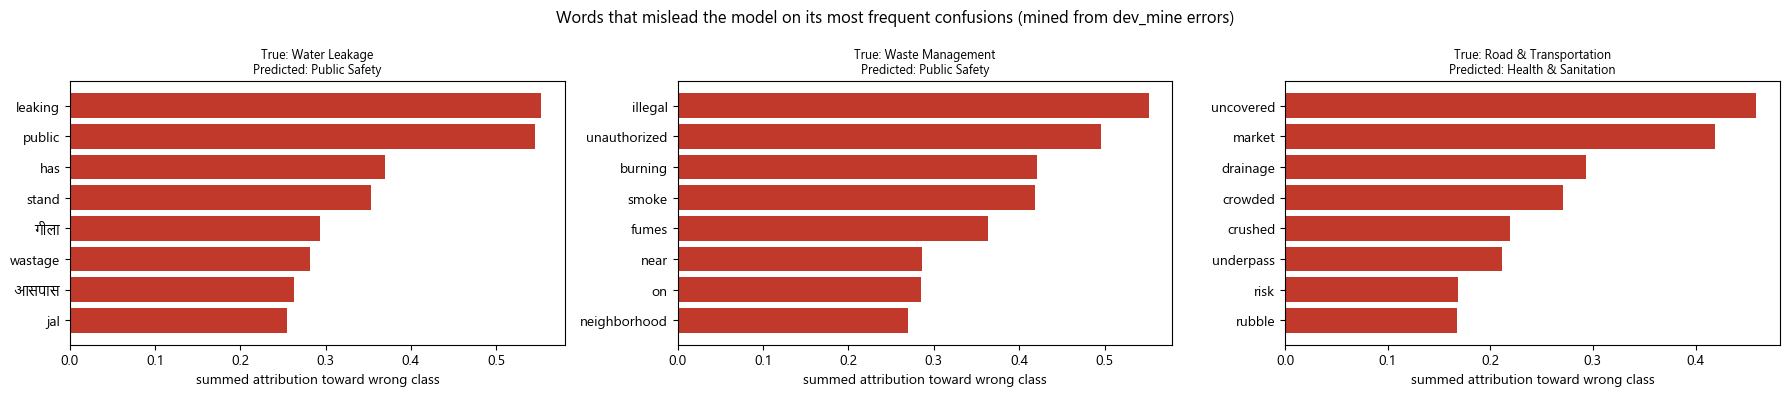

Mined 40 misleading words; top 15: ['public', 'street', 'sewage', 'footpath', 'the', 'illegal', 'emergency', 'sweeping', 'after', 'road', 'has', 'and', 'in', 'from', 'cleaning']
Reference XAI stats: {'top1_concentration': 0.273836225271225, 'single_token_flip_rate': 0.08625}


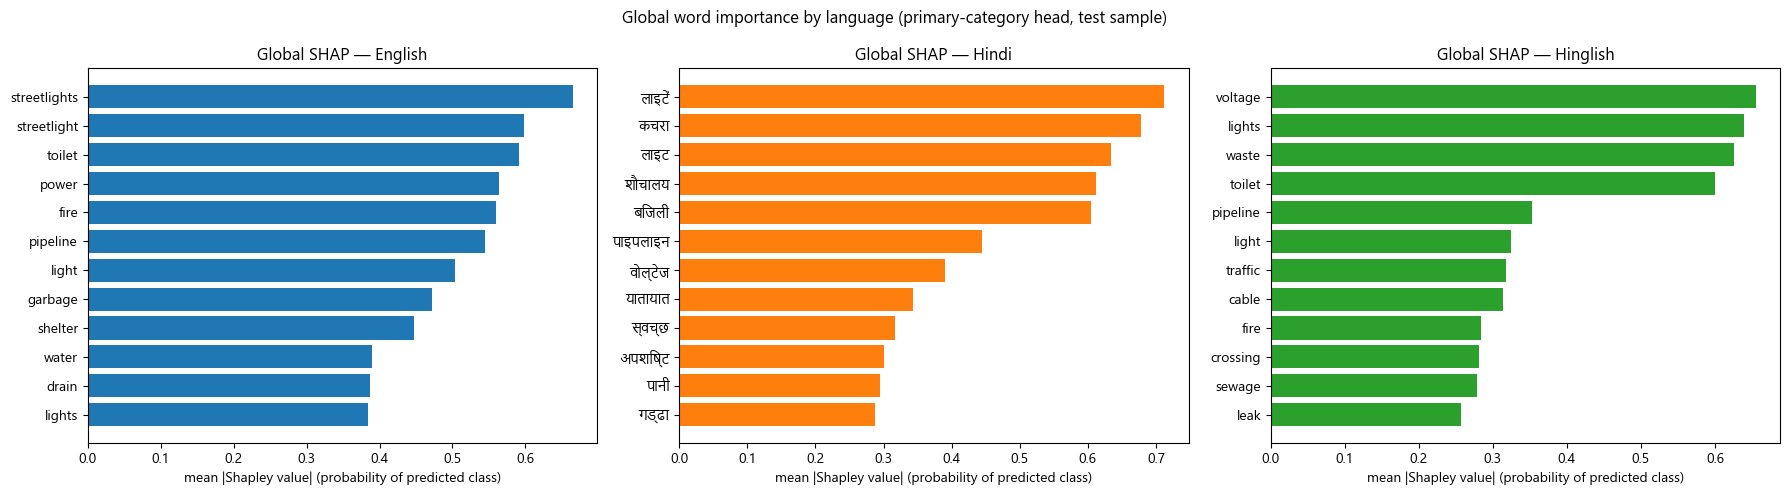

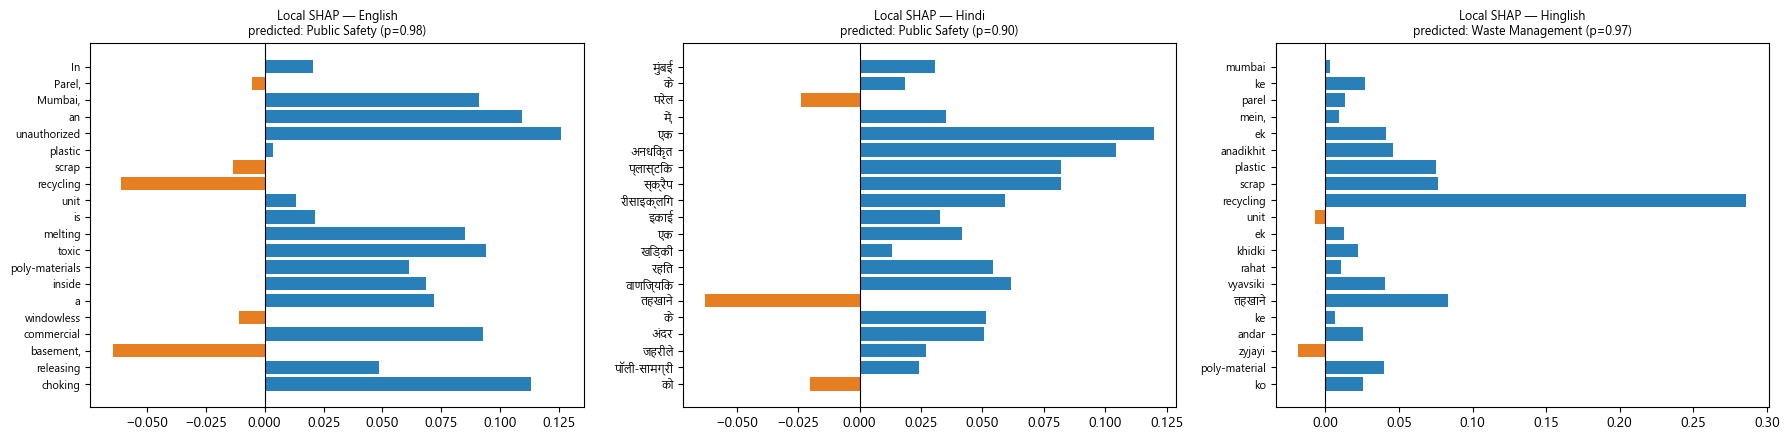

SHAP figures/tables saved under C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\reviewer_study\figs and C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\reviewer_study\tables


In [5]:
# ============================================================================
# PART B.1 — REFERENCE MODEL, SHAP / ATTRIBUTION ANALYSIS (this is where your SHAP results first appear)
# ============================================================================
def make_predictor(model, head='primary', bs=128):
    hi = TASKS.index(head)
    @torch.no_grad()
    def predict(texts):
        model.eval(); texts = list(texts); out = np.zeros((len(texts), model.n_cls[head]), np.float32)
        order = np.argsort([len(t) for t in texts])
        for s in range(0, len(texts), bs):
            ix = order[s:s + bs]
            enc = tok([texts[i] for i in ix], truncation=True, padding=True, max_length=CFG.MAX_LENGTH, return_tensors='pt').to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                lg = model(enc['input_ids'], enc['attention_mask'])[hi]
            out[ix] = torch.softmax(lg.float(), -1).cpu().numpy()
        return out
    return predict

def setup_fonts():
    import matplotlib.font_manager as fm
    have = {f.name for f in fm.fontManager.ttflist}
    for f in ['Noto Sans Devanagari', 'Nirmala UI', 'Mangal', 'Arial Unicode MS', 'DejaVu Sans']:
        if f in have: plt.rcParams['font.family'] = f; return f
setup_fonts()

# ---- reference model: ONE training run (alpha3 = CFG.REF_ALPHA), reused by every later step ----
def ref_ckpt_path(seed): return OUT('ckpt', f'ref_a3_0.5_s{seed}.pt')
REF_ALPHA, REF_SEED = CFG.REF_ALPHA, CFG.REFINE_SEEDS[0]
REF_CKPT = ref_ckpt_path(REF_SEED) if abs(REF_ALPHA - 0.5) < 1e-9 else OUT('ckpt', f'ref_a3_{REF_ALPHA}_s{REF_SEED}.pt')
_t = time.time()
REF_RES = train_run(f'a3_{REF_ALPHA}', REF_SEED, (1, 1, REF_ALPHA), train_df, dev_sel, test_df, epochs=CFG.EPOCHS, save_ckpt=REF_CKPT)
print(f'reference model ready in {(time.time() - _t) / 60:.1f} min')
USE_EXISTING = False   # True => start from your already-trained checkpoint (mixed recipe; the plain/random controls still keep it fair)
if USE_EXISTING and os.path.exists(CFG.EXISTING_CKPT): REF_CKPT = CFG.EXISTING_CKPT
print(f'Reference: alpha3={REF_ALPHA} seed={REF_SEED}  test mt_F1={REF_RES["test"]["mt_f1"]:.4f}  ckpt={REF_CKPT}')

ref_model = build_model(); ref_model.load_state_dict(load_state(REF_CKPT), strict=False); ref_model.eval()
pred_primary = make_predictor(ref_model, 'primary')

# ---- (1) is the cheap occlusion a valid stand-in for Shapley/SHAP?  (justifies using it inside the loop) ----
samp = dev_sel.sample(min(CFG.SHAP_N, len(dev_sel)), random_state=1)['text'].tolist()
occ_s = occlusion_attributions(pred_primary, samp, None, max_words=24, mask_token=MASK)
shp_s = shapley_attributions(pred_primary, samp, None, n_perm=8, max_words=24, mask_token=MASK)
AGREE = agreement(occ_s, shp_s); json.dump(AGREE, open(OUT('xai', 'occlusion_vs_shapley.json'), 'w'))
print('Occlusion vs word-level Shapley:', {k: round(v, 3) if isinstance(v, float) else v for k, v in AGREE.items()})
print('Mean |sum(phi) - (p_full - p_allmasked)| (efficiency check, should be ~0):',
      float(np.mean([abs(a['attr'].sum() - (a['p_full'][a['target']] - pred_primary([' '.join([MASK] * len(a['words']))])[0][a['target']])) for a in shp_s[:10]])))

# ---- (2) Stage-A diagnostics on dev_mine ----
dm = dev_mine.sample(min(CFG.DEV_MINE_N, len(dev_mine)), random_state=0).reset_index(drop=True)
att_dm = occlusion_attributions(pred_primary, dm['text'].tolist(), None, mask_token=MASK)
yhat = np.array([a['target'] for a in att_dm]); ytrue = dm['primary_label'].values
print(f'dev_mine accuracy = {(yhat == ytrue).mean():.4f}  ({(yhat != ytrue).sum()} errors to learn from)')
# coverage check: attribution runs on the first 64 words; make sure that window reproduces the model's real prediction
full_pred = pred_primary(dm['text'].tolist()).argmax(1); cover = float((full_pred == yhat).mean())
print(f'Attribution-window coverage: truncated-text prediction == full-input prediction for {cover:.1%} of examples' +
      ('' if cover >= 0.95 else '  <-- below 95%: raise max_words in occlusion_attributions (pure-function cell) or shorten the input'))

gi = global_importance(att_dm); gi['class'] = gi['cls'].map(lambda c: CLASS_NAMES['primary'][c])
gi.to_csv(OUT('xai', 'global_importance_by_class.csv'), index=False, encoding='utf-8')
print('\nTop-5 globally important words per predicted class:')
for c, d in gi.groupby('class'): print(f'  {c:<38}', ', '.join(d.sort_values('mean_attr', ascending=False).head(5)['word']))

mis0, pairs0 = mine_misleading(att_dm, ytrue)
json.dump({w: list(v) for w, v in mis0.items()}, open(OUT('xai', 'misleading_tokens_ref.json'), 'w'), ensure_ascii=False, indent=1)
top_pairs = sorted(pairs0.items(), key=lambda kv: -sum(kv[1].values()))[:3]
fig, axes = plt.subplots(1, max(len(top_pairs), 1), figsize=(6 * max(len(top_pairs), 1), 4), squeeze=False)
for ax, ((t, p), c) in zip(axes[0], top_pairs):
    items = sorted(c.items(), key=lambda kv: -kv[1])[:8][::-1]
    ax.barh([w for w, _ in items], [v for _, v in items], color='#c0392b')
    ax.set_title(f'True: {CLASS_NAMES["primary"][t][:22]}\nPredicted: {CLASS_NAMES["primary"][p][:22]}', fontsize=9)
    ax.set_xlabel('summed attribution toward wrong class')
plt.suptitle('Words that mislead the model on its most frequent confusions (mined from dev_mine errors)'); plt.tight_layout()
plt.savefig(OUT('figs', 'misleading_tokens.png'), dpi=300, bbox_inches='tight'); plt.show()
print('Mined', len(mis0), 'misleading words; top 15:', list(mis0)[:15])
print('Reference XAI stats:', attribution_stats(att_dm))


# ---- (3) PAPER-STYLE SHAP FIGURES: global importance per language + local explanations (word-level Shapley values) ----
LANG_COLS = {'English': 'text_en', 'Hindi': 'Hindi', 'Hinglish': 'Hinglish'}
shap_sample = test_df.sample(min(CFG.SHAP_N * 5, len(test_df)), random_state=3)     # descriptive only; nothing is selected on it
fig, axes = plt.subplots(1, 3, figsize=(18, 5)); glob_tabs = []
for ax, (lang, col) in zip(axes, LANG_COLS.items()):
    texts = shap_sample[col].astype(str).tolist()
    att = shapley_attributions(pred_primary, texts, None, n_perm=6, max_words=20, mask_token=MASK)
    acc = defaultdict(list)
    for a in att:
        seen = set()
        for w, v in zip(a['words'], a['attr']):
            nw = norm_word(w)
            if len(nw) >= 2 and nw not in seen: seen.add(nw); acc[nw].append(abs(float(v)))
    g = pd.DataFrame([(w, np.mean(v), len(v)) for w, v in acc.items() if len(v) >= 2], columns=['word', 'mean_abs_shap', 'freq'])
    g = g.sort_values('mean_abs_shap', ascending=False).head(12); g['language'] = lang; glob_tabs.append(g)
    ax.barh(g['word'][::-1], g['mean_abs_shap'][::-1], color={'English': '#1f77b4', 'Hindi': '#ff7f0e', 'Hinglish': '#2ca02c'}[lang])
    ax.set_title(f'Global SHAP — {lang}'); ax.set_xlabel('mean |Shapley value| (probability of predicted class)')
plt.suptitle('Global word importance by language (primary-category head, test sample)'); plt.tight_layout()
plt.savefig(OUT('figs', 'shap_global_by_language.png'), dpi=300, bbox_inches='tight'); plt.show()
pd.concat(glob_tabs).to_csv(OUT('tables', 'shap_global_by_language.csv'), index=False, encoding='utf-8')

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (lang, col) in zip(axes, LANG_COLS.items()):
    txt = shap_sample[col].astype(str).iloc[0]
    a = shapley_attributions(pred_primary, [txt], None, n_perm=10, max_words=20, mask_token=MASK)[0]
    vals = a['attr']; ax.barh(range(len(vals))[::-1], vals, color=['#2980b9' if v >= 0 else '#e67e22' for v in vals])
    ax.set_yticks(range(len(vals))[::-1]); ax.set_yticklabels(a['words'], fontsize=8); ax.axvline(0, c='k', lw=.8)
    ax.set_title(f'Local SHAP — {lang}\npredicted: {CLASS_NAMES["primary"][a["target"]][:28]} (p={a["p_full"][a["target"]]:.2f})', fontsize=9)
plt.tight_layout(); plt.savefig(OUT('figs', 'shap_local_examples.png'), dpi=300, bbox_inches='tight'); plt.show()
print('SHAP figures/tables saved under', OUT('figs'), 'and', OUT('tables'))


In [6]:
# ============================================================================
# SHAP-GUIDED REFINEMENT LOOP  (+ plain / random controls)
# ============================================================================
def xai_quality(model, df, n, tag):
    f = OUT('xai', f'quality_{tag}.json')
    if os.path.exists(f): return json.load(open(f))
    sub = df.sample(min(n, len(df)), random_state=0)['text'].tolist()
    pr = make_predictor(model, 'primary'); att = occlusion_attributions(pr, sub, None, mask_token=MASK)
    fa = faithfulness(pr, att, mask_token=MASK)
    res = dict(comp_aopc=fa['comp_aopc'], suff_aopc=fa['suff_aopc'], **attribution_stats(att))
    json.dump(res, open(f, 'w')); return res

def summarise(res, q, rnd, accepted, n_aug, n_mis):
    v = res.get('views', {}).get('hinglish', {})
    return dict(round=rnd, accepted=accepted, aug_rows=n_aug, mislead_words=n_mis, dev_mt_f1=res['dev']['mt_f1'],
                test_mt_f1=res['test']['mt_f1'], f1_primary=res['test']['primary']['f1_macro'],
                f1_subcat=res['test']['subcat']['f1_macro'], f1_severity=res['test']['severity']['f1_macro'],
                hinglish_primary_f1=v.get('primary', {}).get('f1_macro', np.nan), **{k: q[k] for k in q})

def loop_attr(pr, texts, targets=None):
    if CFG.LOOP_ATTR == 'shapley': return shapley_attributions(pr, texts, targets, n_perm=4, max_words=32, mask_token=MASK)
    return occlusion_attributions(pr, texts, targets, mask_token=MASK)

def refine(mode, seed=None, rounds=None):
    assert mode in ('shap', 'random', 'plain'); seed = seed or REF_SEED; rounds = rounds or CFG.ROUNDS
    rng = np.random.RandomState(seed + {'shap': 1, 'random': 2, 'plain': 3}[mode]); rows = []
    state = load_state(REF_CKPT); best_dev = REF_RES['dev']['mt_f1']; prev_ck = None; last_res = REF_RES
    m0 = build_model(); m0.load_state_dict(state, strict=False)
    rows.append(summarise(REF_RES, xai_quality(m0, test_df, CFG.FAITH_N, f'ref_s{seed}'), 0, True, 0, 0)); del m0
    final_tag = f'a3_{REF_ALPHA}'
    for r in range(1, rounds + 1):
        tag = f'refine_{mode}_r{r}'; ck = OUT('ckpt', f'{tag}_s{seed}.pt'); mf = OUT('xai', f'mislead_{mode}_r{r}_s{seed}.json')
        n_aug, n_mis = 0, 0
        if not run_cached(tag, seed, ck, CFG.REFINE_EPOCHS):
            model = build_model(); model.load_state_dict(state, strict=False); pr = make_predictor(model, 'primary')
            aug = train_df.iloc[0:0].copy(); mis = {}
            if mode == 'shap':
                d = dev_mine.sample(min(CFG.DEV_MINE_N, len(dev_mine)), random_state=r)
                att_d = loop_attr(pr, d['text'].tolist(), None)
                mis, _ = mine_misleading(att_d, d['primary_label'].tolist())
                json.dump({w: list(v) for w, v in mis.items()}, open(mf, 'w'), ensure_ascii=False)
                sub = rng.choice(len(train_df), min(CFG.TRAIN_ATTR_N, len(train_df)), replace=False)
                att_t = loop_attr(pr, train_df['text'].iloc[sub].tolist(), train_df['primary_label'].iloc[sub].tolist())
                aug = build_augmented(train_df, sub, att_t, 'shap', mis, CFG.AUG_MAX, rng, MASK)
            elif mode == 'random':
                src = mf.replace('random', 'shap')
                if not os.path.exists(src): src = OUT('xai', f'mislead_shap_r1_s{seed}.json')
                assert os.path.exists(src), "Run refine('shap') first: the random control is matched to its row counts."
                mis = {w: tuple(v) for w, v in json.load(open(src)).items()}
                sub = rng.choice(len(train_df), min(CFG.TRAIN_ATTR_N, len(train_df)), replace=False)
                dummy = [dict(words=train_df['text'].iloc[i].split()[:64], attr=np.zeros(min(64, len(train_df['text'].iloc[i].split())))) for i in sub]
                aug = build_augmented(train_df, sub, dummy, 'random', mis, CFG.AUG_MAX, rng, MASK)
            n_aug, n_mis = len(aug), len(mis)
            aug.to_csv(OUT('xai', f'aug_{mode}_r{r}_s{seed}.csv'), index=False, encoding='utf-8')
            print(f'[{mode}] round {r}: +{n_aug} augmented rows, {n_mis} misleading words')
            data = pd.concat([train_df, aug], ignore_index=True) if n_aug else train_df
            del model; gc.collect(); torch.cuda.empty_cache() if torch.cuda.is_available() else None
        else:
            data = None
            af = OUT('xai', f'aug_{mode}_r{r}_s{seed}.csv')
            n_aug = len(pd.read_csv(af)) if os.path.exists(af) else 0
            n_mis = len(json.load(open(mf))) if os.path.exists(mf) else 0
        res = train_run(tag, seed, (1, 1, REF_ALPHA), data if data is not None else train_df, dev_sel, test_df,
                        epochs=CFG.REFINE_EPOCHS, lr=1e-5, init_state=state, save_ckpt=ck)
        accepted = res['dev']['mt_f1'] > best_dev + 1e-4
        if accepted:
            best_dev, last_res, state = res['dev']['mt_f1'], res, load_state(ck)
            if prev_ck and os.path.exists(prev_ck): os.remove(prev_ck)
            prev_ck = ck; m = build_model(); m.load_state_dict(state, strict=False)
            q = xai_quality(m, test_df, CFG.FAITH_N, f'{mode}_r{r}_s{seed}'); del m
        else:
            q = rows[-1]; q = {k: q[k] for k in ('comp_aopc', 'suff_aopc', 'top1_concentration', 'single_token_flip_rate')}
        rows.append(summarise(res, q, r, accepted, n_aug, n_mis))
        print(f'[{mode}] round {r}: dev {res["dev"]["mt_f1"]:.4f} (best so far {best_dev:.4f}) -> ' + ('ACCEPTED' if accepted else 'rejected, stop'))
        if not accepted: break
    df = pd.DataFrame(rows); df['mode'] = mode; df['seed'] = seed
    last_ok = df[df.accepted].iloc[-1]; df.attrs['final_tag'] = f'refine_{mode}_r{int(last_ok["round"])}' if last_ok['round'] > 0 else final_tag
    return df

refine_tables = {}
for mode in ['shap', 'random', 'plain']:                  # shap first: random control is matched to it
    refine_tables[mode] = refine(mode)
    refine_tables[mode].to_csv(OUT('tables', f'refinement_{mode}.csv'), index=False)
    print(refine_tables[mode].round(4).to_string(index=False), '\n')


[shap] round 1: +3000 augmented rows, 40 misleading words


  refine_shap_r1 s11 ep1: dev mt_f1=0.8743 P=0.9247 S=0.8397 V=0.8584
[shap] round 1: dev 0.8743 (best so far 0.8752) -> rejected, stop
 round  accepted  aug_rows  mislead_words  dev_mt_f1  test_mt_f1  f1_primary  f1_subcat  f1_severity  hinglish_primary_f1  comp_aopc  suff_aopc  top1_concentration  single_token_flip_rate mode  seed
     0      True         0              0     0.8752      0.8584      0.9196     0.8231       0.8324               0.5605     0.3296     0.1814              0.2832                  0.0867 shap    11
     1     False      3000             40     0.8743      0.8649      0.9217     0.8329       0.8403               0.5770     0.3296     0.1814              0.2832                  0.0867 shap    11 

[random] round 1: +3000 augmented rows, 40 misleading words


  refine_random_r1 s11 ep1: dev mt_f1=0.8751 P=0.9250 S=0.8372 V=0.8632
[random] round 1: dev 0.8751 (best so far 0.8752) -> rejected, stop
 round  accepted  aug_rows  mislead_words  dev_mt_f1  test_mt_f1  f1_primary  f1_subcat  f1_severity  hinglish_primary_f1  comp_aopc  suff_aopc  top1_concentration  single_token_flip_rate   mode  seed
     0      True         0              0     0.8752      0.8584      0.9196     0.8231       0.8324               0.5605     0.3296     0.1814              0.2832                  0.0867 random    11
     1     False      3000             40     0.8751      0.8650      0.9208     0.8356       0.8387               0.5663     0.3296     0.1814              0.2832                  0.0867 random    11 

[plain] round 1: +0 augmented rows, 0 misleading words


  refine_plain_r1 s11 ep1: dev mt_f1=0.8740 P=0.9217 S=0.8377 V=0.8626
[plain] round 1: dev 0.8740 (best so far 0.8752) -> rejected, stop
 round  accepted  aug_rows  mislead_words  dev_mt_f1  test_mt_f1  f1_primary  f1_subcat  f1_severity  hinglish_primary_f1  comp_aopc  suff_aopc  top1_concentration  single_token_flip_rate  mode  seed
     0      True         0              0     0.8752      0.8584      0.9196     0.8231       0.8324               0.5605     0.3296     0.1814              0.2832                  0.0867 plain    11
     1     False         0              0     0.8740      0.8657      0.9239     0.8317       0.8414               0.5757     0.3296     0.1814              0.2832                  0.0867 plain    11 



                arm  rounds_accepted  dev_mt_f1  test_mt_f1  d_test_mt_f1  f1_primary  f1_subcat  f1_severity  hinglish_primary_f1  d_hinglish  comp_aopc  suff_aopc  top1_concentration  flip_rate
reference (round 0)                0     0.8752      0.8584           0.0      0.9196     0.8231       0.8324               0.5605         0.0     0.3296     0.1814              0.2832     0.0867
               shap                0     0.8752      0.8584           0.0      0.9196     0.8231       0.8324               0.5605         0.0     0.3296     0.1814              0.2832     0.0867
             random                0     0.8752      0.8584           0.0      0.9196     0.8231       0.8324               0.5605         0.0     0.3296     0.1814              0.2832     0.0867
              plain                0     0.8752      0.8584           0.0      0.9196     0.8231       0.8324               0.5605         0.0     0.3296     0.1814              0.2832     0.0867

Paired bootstrap, d

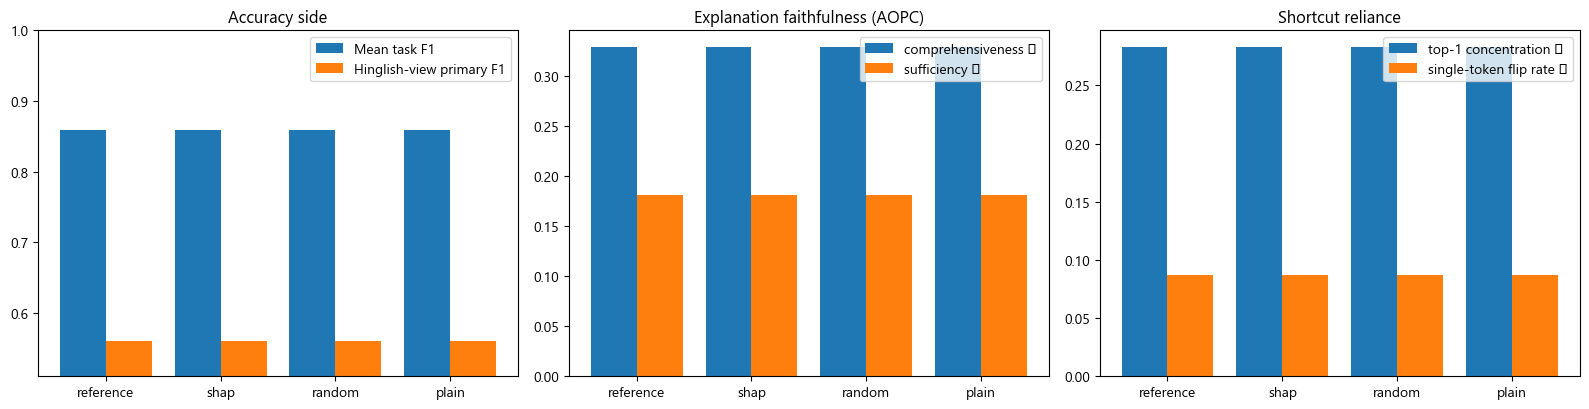

In [7]:
# ============================================================================
# REFINEMENT RESULTS: final-round comparison, controls, significance, faithfulness
# ============================================================================
final = []
for mode, df in refine_tables.items():
    ok = df[df.accepted]; last = ok.iloc[-1]; first = df.iloc[0]
    final.append(dict(arm=mode, rounds_accepted=int(last['round']), dev_mt_f1=last['dev_mt_f1'], test_mt_f1=last['test_mt_f1'],
                      d_test_mt_f1=last['test_mt_f1'] - first['test_mt_f1'], f1_primary=last['f1_primary'], f1_subcat=last['f1_subcat'],
                      f1_severity=last['f1_severity'], hinglish_primary_f1=last['hinglish_primary_f1'],
                      d_hinglish=last['hinglish_primary_f1'] - first['hinglish_primary_f1'],
                      comp_aopc=last['comp_aopc'], suff_aopc=last['suff_aopc'],
                      top1_concentration=last['top1_concentration'], flip_rate=last['single_token_flip_rate']))
final_df = pd.DataFrame(final); ref_row = refine_tables['shap'].iloc[0]
final_df.loc[-1] = dict(arm='reference (round 0)', rounds_accepted=0, dev_mt_f1=ref_row['dev_mt_f1'], test_mt_f1=ref_row['test_mt_f1'],
                        d_test_mt_f1=0.0, f1_primary=ref_row['f1_primary'], f1_subcat=ref_row['f1_subcat'], f1_severity=ref_row['f1_severity'],
                        hinglish_primary_f1=ref_row['hinglish_primary_f1'], d_hinglish=0.0, comp_aopc=ref_row['comp_aopc'],
                        suff_aopc=ref_row['suff_aopc'], top1_concentration=ref_row['top1_concentration'], flip_rate=ref_row['single_token_flip_rate'])
final_df = final_df.sort_index().reset_index(drop=True); final_df.to_csv(OUT('tables', 'refinement_summary.csv'), index=False)
print(final_df.round(4).to_string(index=False))

# paired bootstrap on the final models' test predictions (same test examples)
def final_npz(mode, df):
    last = int(df[df.accepted].iloc[-1]['round'])
    return OUT('preds', f'a3_{REF_ALPHA}' + f'_s{REF_SEED}.npz') if last == 0 \
        else OUT('preds', f'refine_{mode}_r{last}_s{REF_SEED}.npz')
npz = {m: final_npz(m, d) for m, d in refine_tables.items()}; npz['ref'] = OUT('preds', f'a3_{REF_ALPHA}' + f'_s{REF_SEED}.npz')
print('\nPaired bootstrap, difference in mean-of-3-tasks Macro-F1 (95% CI):')
for a, b in [('shap', 'ref'), ('shap', 'random'), ('shap', 'plain'), ('random', 'plain')]:
    if os.path.exists(npz[a]) and os.path.exists(npz[b]):
        m, lo, hi = paired_bootstrap(npz[a], npz[b], 1000)
        print(f'  {a:>6} - {b:<6}: {m:+.4f}  [{lo:+.4f}, {hi:+.4f}]  ' + ('SIGNIFICANT' if lo > 0 or hi < 0 else 'n.s.'))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2)); x = np.arange(len(final_df)); lab = [a.replace(' (round 0)', '') for a in final_df.arm]
ax[0].bar(x - .2, final_df.test_mt_f1, .4, label='Mean task F1'); ax[0].bar(x + .2, final_df.hinglish_primary_f1, .4, label='Hinglish-view primary F1')
ax[0].set_xticks(x); ax[0].set_xticklabels(lab); ax[0].set_ylim(max(0, final_df[['test_mt_f1', 'hinglish_primary_f1']].min().min() - .05), 1); ax[0].legend(); ax[0].set_title('Accuracy side')
ax[1].bar(x - .2, final_df.comp_aopc, .4, label='comprehensiveness ↑'); ax[1].bar(x + .2, final_df.suff_aopc, .4, label='sufficiency ↓')
ax[1].set_xticks(x); ax[1].set_xticklabels(lab); ax[1].legend(); ax[1].set_title('Explanation faithfulness (AOPC)')
ax[2].bar(x - .2, final_df.top1_concentration, .4, label='top-1 concentration ↓'); ax[2].bar(x + .2, final_df.flip_rate, .4, label='single-token flip rate ↓')
ax[2].set_xticks(x); ax[2].set_xticklabels(lab); ax[2].legend(); ax[2].set_title('Shortcut reliance')
plt.tight_layout(); plt.savefig(OUT('figs', 'refinement_comparison.png'), dpi=300, bbox_inches='tight'); plt.show()


In [8]:
# ============================================================================
# ATTRIBUTION-MINED LEXICON / ONTOLOGY CONSTRAINT  (Reviewer 1, comment 7)
# Training-free post-hoc layer:  score_c(x) = log p_c(x) + beta * lexicon_c(x);  beta chosen on dev_sel only.
# ============================================================================
# Optional hand-written domain ontology: {"class name exactly as in CLASS_NAMES['primary']": ["keyword", ...]}
MANUAL_ONTOLOGY = {}   # e.g. {"Waste Management": ["garbage", "kachra", "कचरा"], "Health and Sanitation": ["sanitation", "toilet", "शौचालय"]}
manual = {CLASS_NAMES['primary'].index(k): v for k, v in MANUAL_ONTOLOGY.items() if k in CLASS_NAMES['primary']}

# best available model = last accepted SHAP-guided round, else the reference
sh = refine_tables['shap']; last_r = int(sh[sh.accepted].iloc[-1]['round'])
LEX_CKPT = OUT('ckpt', f'refine_shap_r{last_r}_s{REF_SEED}.pt') if last_r > 0 and os.path.exists(OUT('ckpt', f'refine_shap_r{last_r}_s{REF_SEED}.pt')) else REF_CKPT
lex_model = build_model(); lex_model.load_state_dict(load_state(LEX_CKPT), strict=False); lex_pred = make_predictor(lex_model, 'primary')

rng = np.random.RandomState(7); sub = rng.choice(len(train_df), min(CFG.TRAIN_ATTR_N, len(train_df)), replace=False)
ytr = train_df['primary_label'].iloc[sub].tolist()
att_lex = occlusion_attributions(lex_pred, train_df['text'].iloc[sub].tolist(), ytr, mask_token=MASK)
lex = build_lexicon(att_lex, ytr, N_CLS['primary'], manual=manual)
print(f'Lexicon: {len(lex)} words'); 
for c in range(N_CLS['primary']):
    ws = [w for w, (cc, _) in sorted(lex.items(), key=lambda kv: -kv[1][1]) if cc == c][:6]
    print(f'  {CLASS_NAMES["primary"][c]:<38}', ', '.join(ws))
json.dump({w: [CLASS_NAMES['primary'][c], v] for w, (c, v) in lex.items()}, open(OUT('xai', 'lexicon.json'), 'w'), ensure_ascii=False, indent=1)

def lex_eval(df, betas):
    P = lex_pred(df['text'].tolist()); L = lexicon_scores(df['text'].tolist(), lex, N_CLS['primary']); y = df['primary_label'].values
    return {b: (np.log(P + 1e-9) + b * L).argmax(1) for b in betas}, y
BETAS = [0, 0.5, 1, 2, 4, 8, 16, 32]
pd_, yd = lex_eval(dev_sel, BETAS); dev_f1 = {b: f1_score(yd, p, average='macro') for b, p in pd_.items()}
beta_star = max(dev_f1, key=dev_f1.get); print('dev_sel primary macro-F1 by beta:', {b: round(v, 4) for b, v in dev_f1.items()}, '-> beta* =', beta_star)
pt_, yt = lex_eval(test_df, [0, beta_star])
cm0, cm1 = confusion_matrix(yt, pt_[0], labels=range(N_CLS['primary'])), confusion_matrix(yt, pt_[beta_star], labels=range(N_CLS['primary']))
off0, off1 = cm0.sum() - np.trace(cm0), cm1.sum() - np.trace(cm1)
LEX_RES = dict(beta_star=beta_star, f1_before=f1_score(yt, pt_[0], average='macro'), f1_after=f1_score(yt, pt_[beta_star], average='macro'),
               acc_before=accuracy_score(yt, pt_[0]), acc_after=accuracy_score(yt, pt_[beta_star]), errors_before=int(off0), errors_after=int(off1))
# focus on the dominant confusion pair
pair = max(((i, j) for i in range(N_CLS['primary']) for j in range(N_CLS['primary']) if i != j), key=lambda ij: cm0[ij] + cm0[ij[::-1]])
LEX_RES['pair'] = [CLASS_NAMES['primary'][pair[0]], CLASS_NAMES['primary'][pair[1]]]
LEX_RES['pair_errors_before'] = int(cm0[pair] + cm0[pair[::-1]]); LEX_RES['pair_errors_after'] = int(cm1[pair] + cm1[pair[::-1]])
json.dump(LEX_RES, open(OUT('tables', 'lexicon_constraint.json'), 'w'), indent=1)
print(json.dumps(LEX_RES, indent=1))


Lexicon: 247 words
  Electricity                            transformer, streetlights, power, lights, cable, pole
  Encroachment & Illegal Construction    erected, encroachment, legal, built, whether, unauthorized
  Health & Sanitation                    toilet, wash, restroom, शौचालय, basin, plumbing
  Others                                 crematorium, pigs, shelter, dogs, 12, information
  Public Safety                          extinguisher, fire, routes, फूड, अग्निशामक, evacuation
  Road & Transportation                  potholes, surveillance, cameras, motorists, parking, hole
  Waste Management                       spot, pest, infestation, recycling, garbage, waste
  Water Leakage                          leak, steady, पाइपलाइन, tap, सर्विस, दबाव
dev_sel primary macro-F1 by beta: {0: 0.9244, 0.5: 0.9244, 1: 0.9244, 2: 0.9244, 4: 0.9244, 8: 0.925, 16: 0.9251, 32: 0.9247} -> beta* = 16
{
 "beta_star": 16,
 "f1_before": 0.9195967401945918,
 "f1_after": 0.921753126272396,
 "acc_befo

## Part A — α₃ study (long-running; run last) (Reviewer 1, comment 4)

Total loss: `L = α₁·L_primary + α₂·L_subcat + α₃·L_severity` with α₁=α₂=1. Three independent lines of evidence are produced for the chosen α₃:

1. **Empirical sensitivity** — every α₃ retrained from scratch over several seeds, all three tasks reported as Macro-F1 (the old Table 19 used overall accuracy only), selected on **dev**, with paired bootstrap tests against α₃ = 0.5.
2. **Gradient-balance argument** — gradient norms of each task loss w.r.t. the shared layer give the weight that equalises task pull: `α₃ ≈ α₁·‖g_primary‖ / ‖g_severity‖`; gradient cosines show whether tasks conflict.
3. **Learned-uncertainty weights** — homoscedastic task uncertainty (Kendall & Gal 2018) learns the weights from data; `exp(−s_sev)/exp(−s_pri)` is a data-driven estimate of α₃/α₁.

> ⚠ Your notebook's earlier "loss-weight ablation" (old cell 26) re-evaluated **one** trained model, so every α₃ gave identical numbers. This section replaces it with genuine retraining.


In [9]:
# ============================================================================
# PART A (long-running, run LAST) — α3 SWEEP  (+ uncertainty-weighting arm + true single-task arms)
# resumable: finished runs are skipped.  Reference checkpoints (alpha=0.5) are saved for Part B.
# ============================================================================
all_runs = []
for seed in CFG.SEEDS:
    for a3 in CFG.ALPHAS:
        ck = ref_ckpt_path(seed) if abs(a3 - 0.5) < 1e-9 else None
        all_runs.append(train_run(f'a3_{a3}', seed, (1.0, 1.0, a3), train_df, dev_sel, test_df,
                                  epochs=CFG.EPOCHS, save_ckpt=ck, do_views=(ck is not None)))
    if CFG.RUN_UNCERTAINTY:
        all_runs.append(train_run('uncertainty', seed, (1, 1, 1), train_df, dev_sel, test_df,
                                  epochs=CFG.EPOCHS, uncertainty=True, do_views=False))
    if CFG.RUN_SINGLE_TASK:       # true single-task models: other task losses get weight 0 -> encoder sees ONLY that task
        for t, al in [('primary', (1, 0, 0)), ('subcat', (0, 1, 0)), ('severity', (0, 0, 1))]:
            all_runs.append(train_run(f'single_{t}', seed, al, train_df, dev_sel, test_df,
                                      epochs=CFG.EPOCHS, select_task=t, grad_diag=False, do_views=False))
print(f'{len(all_runs)} runs available in {OUT("runs")}')


  a3_0.25 s11 ep1: dev mt_f1=0.7232 P=0.8961 S=0.7282 V=0.5453


  a3_0.25 s11 ep2: dev mt_f1=0.8374 P=0.9179 S=0.8395 V=0.7548


  a3_0.25 s11 ep3: dev mt_f1=0.8476 P=0.9242 S=0.8443 V=0.7743


  a3_1.0 s11 ep1: dev mt_f1=0.8050 P=0.8924 S=0.6829 V=0.8397


  a3_1.0 s11 ep2: dev mt_f1=0.8707 P=0.9206 S=0.8162 V=0.8752


  a3_1.0 s11 ep3: dev mt_f1=0.8744 P=0.9200 S=0.8224 V=0.8808
3 runs available in C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\reviewer_study\runs


 alpha3  dev_mt_f1_mean  dev_mt_f1_std  test_mt_f1_mean  test_mt_f1_std  test_mt_acc_mean  test_mt_acc_std  f1_primary_mean  f1_primary_std  f1_subcat_mean  f1_subcat_std  f1_severity_mean  f1_severity_std  acc_primary_mean  acc_primary_std  acc_subcat_mean  acc_subcat_std  acc_severity_mean  acc_severity_std
   0.00          0.7037            NaN           0.7000             NaN            0.7045              NaN           0.9284             NaN          0.8413            NaN            0.3304              NaN            0.9275              NaN           0.8557             NaN             0.3304               NaN
   0.25          0.8476            NaN           0.8374             NaN            0.8456              NaN           0.9254             NaN          0.8278            NaN            0.7591              NaN            0.9242              NaN           0.8435             NaN             0.7691               NaN
   0.50          0.8752            NaN           0.8584            

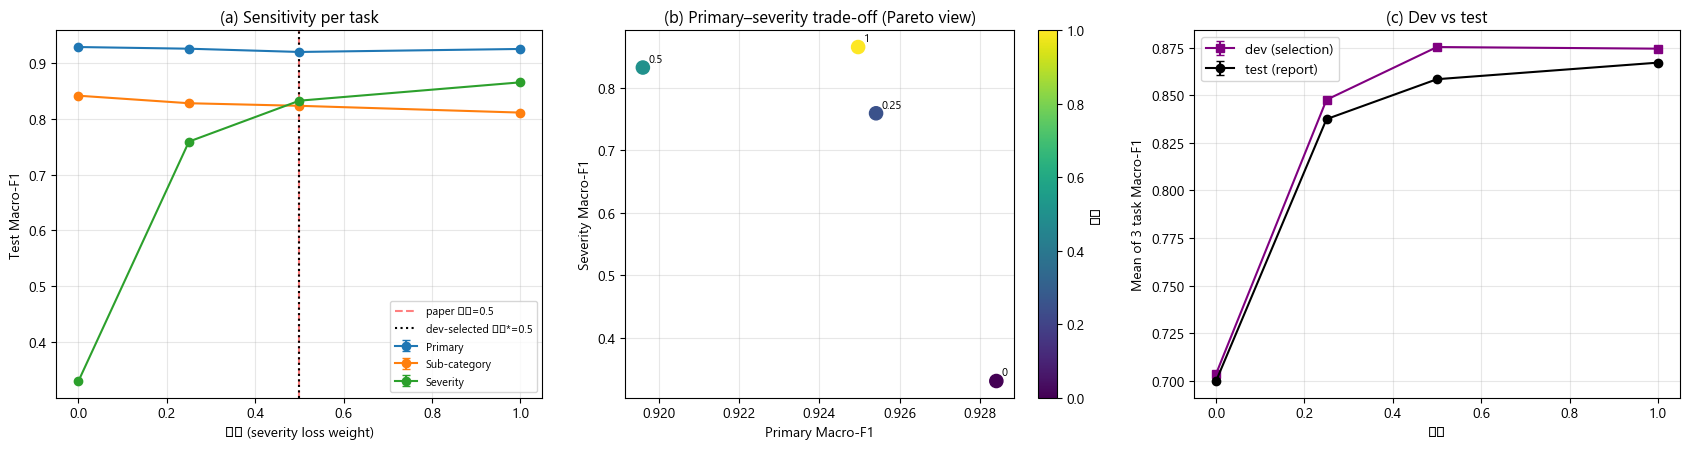


Gradient diagnostics at the shared layer (mean over seeds):
          n_p     n_s     n_v  cos_ps  cos_pv  cos_sv  alpha3_balance
epoch                                                                
1      1.0457  1.5614  1.3392  0.0411 -0.0141 -0.0022          0.7808
2      0.8691  1.1678  1.2674  0.0444  0.0012 -0.0001          0.6857
3      0.8035  1.1586  1.1884  0.0482 -0.0010  0.0006          0.6761


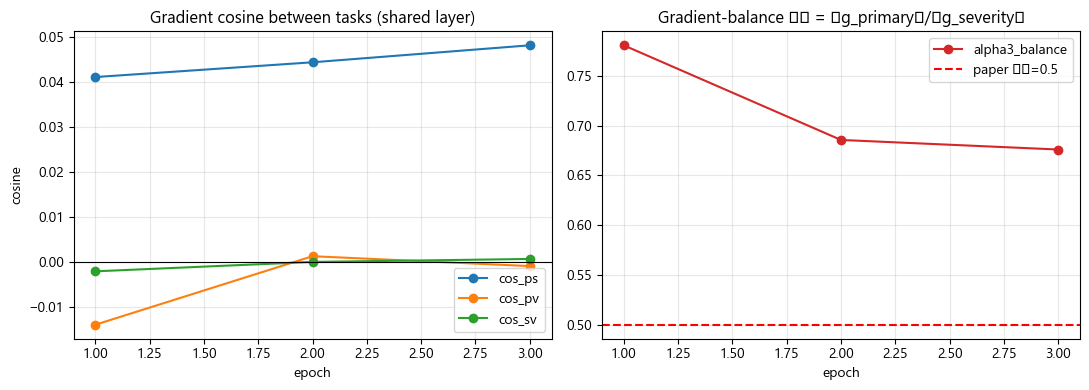


Saved: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\hienbert_results_CommonDataset\reviewer_study\tables\table19_alpha3.tex


In [10]:
# ============================================================================
# α3 ANALYSIS: tables, significance, Pareto/sensitivity figures, justification
# ============================================================================
def load_runs(prefix):
    rs = []
    for f in sorted(os.listdir(OUT('runs'))):
        if f.startswith(prefix) and f.endswith('.json'): rs.append(json.load(open(OUT('runs', f))))
    return rs

rows = []
for r in load_runs('a3_'):
    rows.append(dict(alpha3=r['alphas'][2], seed=r['seed'], best_epoch=r['best_epoch'],
                     dev_mt_f1=r['dev']['mt_f1'], test_mt_f1=r['test']['mt_f1'], test_mt_acc=r['test']['mt_acc'],
                     f1_primary=r['test']['primary']['f1_macro'], f1_subcat=r['test']['subcat']['f1_macro'],
                     f1_severity=r['test']['severity']['f1_macro'], acc_primary=r['test']['primary']['acc'],
                     acc_subcat=r['test']['subcat']['acc'], acc_severity=r['test']['severity']['acc']))
runs_df = pd.DataFrame(rows)
assert len(runs_df), 'No a3_* runs found - run cell 4 first.'
agg = runs_df.groupby('alpha3').agg(['mean', 'std']).drop(columns=['seed', 'best_epoch'], level=0)
agg.columns = ['_'.join(c) for c in agg.columns]; agg = agg.reset_index()
agg.to_csv(OUT('tables', 'alpha3_sweep_summary.csv'), index=False)
pd.set_option('display.width', 200); print(agg.round(4).to_string(index=False))

# ---- dev-based selection + plateau (all alphas within 1 SE of the best on DEV) ----
g = runs_df.groupby('alpha3')['dev_mt_f1']; dev_mean, dev_se = g.mean(), g.std().fillna(0) / np.sqrt(g.count())
a_star = float(dev_mean.idxmax()); thr = dev_mean.max() - dev_se[a_star]
plateau = sorted(float(a) for a in dev_mean.index if dev_mean[a] >= thr)
print(f'\nDev-selected alpha3* = {a_star}   |  plateau (within 1 SE of best on dev): {plateau}')
print('alpha3 = 0.5 is ' + ('INSIDE' if any(abs(a - 0.5) < 1e-9 for a in plateau) else 'OUTSIDE') + ' the plateau.')
if abs(a_star - CFG.REF_ALPHA) > 1e-9: print(f'NOTE: Part B used the reference alpha3={CFG.REF_ALPHA}. If you want the loop at alpha3*={a_star}, set CFG.REF_ALPHA={a_star} and re-run Part B.')

# ---- paired bootstrap vs alpha3=0.5 (pooled over seeds) ----
sig = []
base = {s: OUT('preds', f'a3_0.5_s{s}.npz') for s in CFG.SEEDS}
for a in CFG.ALPHAS:
    if abs(a - 0.5) < 1e-9: continue
    ds = []
    for s in CFG.SEEDS:
        fa, fb = OUT('preds', f'a3_{a}_s{s}.npz'), base[s]
        if os.path.exists(fa) and os.path.exists(fb): ds.append(paired_bootstrap(fa, fb, 500, s))
    if ds: sig.append(dict(alpha3=a, diff_vs_0p5=np.mean([d[0] for d in ds]), ci_lo=np.mean([d[1] for d in ds]),
                           ci_hi=np.mean([d[2] for d in ds]),
                           significant=bool(np.mean([d[1] for d in ds]) > 0 or np.mean([d[2] for d in ds]) < 0)))
sig_df = pd.DataFrame(sig); sig_df.to_csv(OUT('tables', 'alpha3_vs_0p5_bootstrap.csv'), index=False)
print('\nPaired bootstrap (mean-of-3-tasks Macro-F1, alpha3 minus 0.5):\n', sig_df.round(4).to_string(index=False))

# ---- figures ----
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for t, nm, c in [('f1_primary', 'Primary', '#1f77b4'), ('f1_subcat', 'Sub-category', '#ff7f0e'), ('f1_severity', 'Severity', '#2ca02c')]:
    ax[0].errorbar(agg['alpha3'], agg[f'{t}_mean'], yerr=agg[f'{t}_std'].fillna(0), marker='o', capsize=3, label=nm, color=c)
ax[0].axvline(0.5, ls='--', c='r', alpha=.5, label='paper α₃=0.5'); ax[0].axvline(a_star, ls=':', c='k', label=f'dev-selected α₃*={a_star}')
ax[0].set_xlabel('α₃ (severity loss weight)'); ax[0].set_ylabel('Test Macro-F1'); ax[0].set_title('(a) Sensitivity per task'); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
sc = ax[1].scatter(agg['f1_primary_mean'], agg['f1_severity_mean'], c=agg['alpha3'], cmap='viridis', s=90)
for _, r in agg.iterrows(): ax[1].annotate(f"{r['alpha3']:g}", (r['f1_primary_mean'], r['f1_severity_mean']), xytext=(4, 4), textcoords='offset points', fontsize=8)
ax[1].set_xlabel('Primary Macro-F1'); ax[1].set_ylabel('Severity Macro-F1'); ax[1].set_title('(b) Primary–severity trade-off (Pareto view)'); plt.colorbar(sc, ax=ax[1], label='α₃'); ax[1].grid(alpha=.3)
ax[2].errorbar(agg['alpha3'], agg['dev_mt_f1_mean'], yerr=agg['dev_mt_f1_std'].fillna(0), marker='s', capsize=3, color='purple', label='dev (selection)')
ax[2].errorbar(agg['alpha3'], agg['test_mt_f1_mean'], yerr=agg['test_mt_f1_std'].fillna(0), marker='o', capsize=3, color='k', label='test (report)')
ax[2].set_xlabel('α₃'); ax[2].set_ylabel('Mean of 3 task Macro-F1'); ax[2].set_title('(c) Dev vs test'); ax[2].legend(); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT('figs', 'alpha3_sensitivity.png'), dpi=300, bbox_inches='tight'); plt.show()

# ---- (2) gradient-balance + conflict diagnostics (runs at the paper's alpha3 = 0.5) ----
gb = []
for r in load_runs('a3_0.5_'):
    for h in r['history']:
        if 'grad' in h: gb.append(dict(seed=r['seed'], epoch=h['epoch'], **h['grad']))
if gb:
    gb = pd.DataFrame(gb); gb['alpha3_balance'] = gb['n_p'] / gb['n_v']
    gb.to_csv(OUT('tables', 'gradient_diagnostics.csv'), index=False)
    print('\nGradient diagnostics at the shared layer (mean over seeds):')
    print(gb.groupby('epoch')[['n_p', 'n_s', 'n_v', 'cos_ps', 'cos_pv', 'cos_sv', 'alpha3_balance']].mean().round(4).to_string())
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    m = gb.groupby('epoch')[['cos_ps', 'cos_pv', 'cos_sv']].mean(); m.plot(ax=ax[0], marker='o'); ax[0].axhline(0, c='k', lw=.8)
    ax[0].set_title('Gradient cosine between tasks (shared layer)'); ax[0].set_ylabel('cosine'); ax[0].grid(alpha=.3)
    gb.groupby('epoch')['alpha3_balance'].mean().plot(ax=ax[1], marker='o', color='C3'); ax[1].axhline(0.5, ls='--', c='r', label='paper α₃=0.5')
    ax[1].set_title('Gradient-balance α₃ = ‖g_primary‖/‖g_severity‖'); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.savefig(OUT('figs', 'gradient_diagnostics.png'), dpi=300, bbox_inches='tight'); plt.show()

# ---- (3) uncertainty weighting ----
ur = load_runs('uncertainty_')
if ur:
    W = np.array([r['learned_w'] for r in ur]); eff = W[:, 2] / W[:, 0]
    print(f'\nLearned uncertainty weights (primary, subcat, severity), mean over seeds: {W.mean(0).round(3)}')
    print(f'Effective alpha3/alpha1 = {eff.mean():.3f} ± {eff.std():.3f}   (test mt_F1 = {np.mean([r["test"]["mt_f1"] for r in ur]):.4f})')

# ---- single vs multi-task (Reviewer 2, comment 2) ----
st = {t: load_runs(f'single_{t}_') for t in TASKS}
if all(st.values()):
    mt = [r for r in load_runs('a3_0.5_')]
    tab = []
    for t in TASKS:
        mt_f = [r['test'][t]['f1_macro'] for r in mt]; st_f = [r['test'][t]['f1_macro'] for r in st[t]]
        tab.append(dict(task=t, multi_task=np.mean(mt_f), multi_std=np.std(mt_f), single_task=np.mean(st_f), single_std=np.std(st_f),
                        gain_pts=100 * (np.mean(mt_f) - np.mean(st_f))))
    mt_df = pd.DataFrame(tab); mt_df.to_csv(OUT('tables', 'multitask_vs_singletask.csv'), index=False)
    print('\nMulti-task (alpha3=0.5) vs true single-task, Macro-F1 (mean/std over seeds):\n', mt_df.round(4).to_string(index=False))

# ---- LaTeX table for the paper (replaces old Table 19) ----
with open(OUT('tables', 'table19_alpha3.tex'), 'w') as f:
    f.write('\\begin{tabular}{lcccc}\n\\hline\n$\\alpha_3$ & Primary F1 & Sub-cat F1 & Severity F1 & Mean F1 \\\\\n\\hline\n')
    for _, r in agg.iterrows():
        f.write(f"{r['alpha3']:g} & {r['f1_primary_mean']:.4f}$\\pm${np.nan_to_num(r['f1_primary_std']):.4f} & "
                f"{r['f1_subcat_mean']:.4f}$\\pm${np.nan_to_num(r['f1_subcat_std']):.4f} & "
                f"{r['f1_severity_mean']:.4f}$\\pm${np.nan_to_num(r['f1_severity_std']):.4f} & {r['test_mt_f1_mean']:.4f} \\\\\n")
    f.write('\\hline\n\\end{tabular}\n')
print('\nSaved:', OUT('tables', 'table19_alpha3.tex'))


## Part C — Hinglish failure analysis and remedy (Reviewer 1 comment 3, Reviewer 2 comment 1)

Language-view Macro-F1 of the reference model (mean of 3 tasks / primary):
{'concat': (0.8584, 0.9196), 'english': (0.8205, 0.8944), 'hindi': (0.6793, 0.7842), 'hinglish': (0.4376, 0.5605)}
  Spearman(subword fragmentation, Hinglish error) = +0.201
  Spearman(English-lexical share, Hinglish error) = -0.320
  Spearman(length (words), Hinglish error) = +0.088
               factor  bin    n  hinglish_error  english_error
subword fragmentation  low 1018           0.310          0.083
subword fragmentation  mid 1012           0.508          0.114
subword fragmentation high 1006           0.541          0.120
English-lexical share  low 1015           0.604          0.117
English-lexical share  mid 1012           0.500          0.103
English-lexical share high 1009           0.253          0.097
       length (words)  low 1094           0.386          0.112
       length (words)  mid  967           0.468          0.085
       length (words) high  975           0.512          0.120

Top Hingl

  viewdrop_p0.5 s11 ep1: dev mt_f1=0.7469 P=0.8837 S=0.6206 V=0.7365


  viewdrop_p0.5 s11 ep2: dev mt_f1=0.8418 P=0.9173 S=0.7872 V=0.8208


  viewdrop_p0.5 s11 ep3: dev mt_f1=0.8515 P=0.9177 S=0.8043 V=0.8325

 view                         concat  english   hindi  hinglish
model                                                         
reference (concat training)  0.9196   0.8944  0.7842    0.5605
view-dropout p=0.5           0.9170   0.9008  0.8700    0.7982


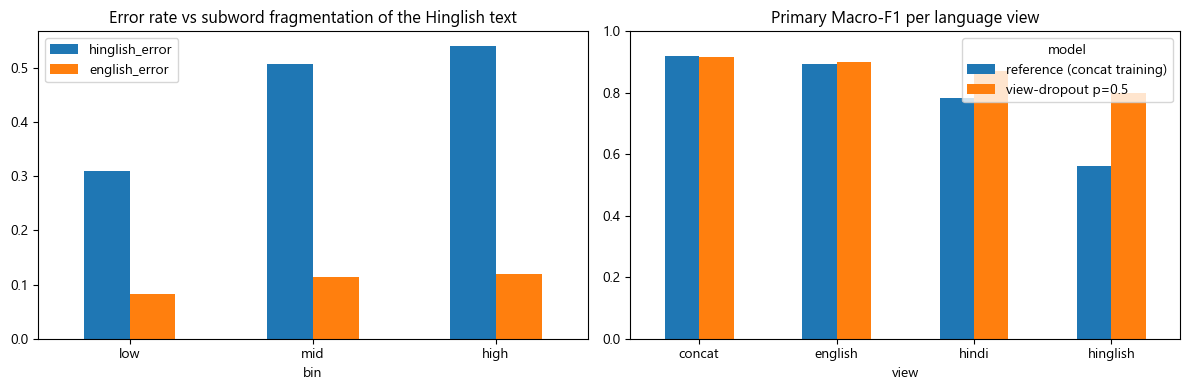

In [11]:
# ============================================================================
# HINGLISH FAILURE ANALYSIS + REMEDY  (Reviewer 1 comment 3, Reviewer 2 comment 1)
# ============================================================================
# KEY FACT about the original pipeline: training text = title + English + Hindi + Hinglish CONCATENATED, but language-wise
# evaluation feeds ONE column at a time -> an input-distribution shift the model never saw. The `viewdrop` arm tests the fix.
print('Language-view Macro-F1 of the reference model (mean of 3 tasks / primary):')
V = REF_RES['views']; print({k: (round(v['mt_f1'], 4), round(v['primary']['f1_macro'], 4)) for k, v in V.items()})

hl = test_df.copy(); en_txt, hg_txt = hl['text_en'].astype(str), hl['Hinglish'].astype(str)
P_h = make_predictor(ref_model, 'primary')
ph = P_h(hg_txt.tolist()).argmax(1); pe = P_h(en_txt.tolist()).argmax(1); y = hl['primary_label'].values
hl['err_hinglish'] = (ph != y).astype(int); hl['err_english'] = (pe != y).astype(int)
hl['frag'] = [len(tok.tokenize(t)) / max(1, len(t.split())) for t in hg_txt]                       # subword fragmentation ratio
hl['eng_overlap'] = [len({norm_word(w) for w in h.split()} & {norm_word(w) for w in e.split()}) / max(1, len(h.split())) for h, e in zip(hg_txt, en_txt)]  # lexical share shared with English (code-mix proxy)
hl['n_words'] = [len(t.split()) for t in hg_txt]
rows = []
for col, nm in [('frag', 'subword fragmentation'), ('eng_overlap', 'English-lexical share'), ('n_words', 'length (words)')]:
    try: hl['bin'] = pd.qcut(hl[col], 3, labels=['low', 'mid', 'high'], duplicates='drop')
    except ValueError: continue
    for b, d in hl.groupby('bin'): rows.append(dict(factor=nm, bin=b, n=len(d), hinglish_error=d.err_hinglish.mean(), english_error=d.err_english.mean()))
    rho = stats.spearmanr(hl[col], hl.err_hinglish)[0]; print(f'  Spearman({nm}, Hinglish error) = {rho:+.3f}')
fail = pd.DataFrame(rows); fail.to_csv(OUT('tables', 'hinglish_failure_factors.csv'), index=False); print(fail.round(3).to_string(index=False))

def top_confusions(y, p, k=5):
    cm = confusion_matrix(y, p, labels=range(N_CLS['primary'])); np.fill_diagonal(cm, 0)
    return [(CLASS_NAMES['primary'][i][:26], CLASS_NAMES['primary'][j][:26], int(cm[i, j])) for i, j in zip(*np.unravel_index(np.argsort(-cm, axis=None)[:k], cm.shape))]
print('\nTop Hinglish confusions:', top_confusions(y, ph)); print('Top English confusions :', top_confusions(y, pe))

# which words mislead the model on Hinglish errors? (attribution-based error analysis)
err_ix = np.where(ph != y)[0][:600]
if len(err_ix):
    att_h = occlusion_attributions(P_h, [hg_txt.iloc[i] for i in err_ix], None, mask_token=MASK)
    mis_h, _ = mine_misleading(att_h, y[err_ix].tolist(), min_count=2)
    json.dump({w: list(v) for w, v in mis_h.items()}, open(OUT('xai', 'hinglish_misleading_tokens.json'), 'w'), ensure_ascii=False, indent=1)
    print('Words that mislead on Hinglish errors:', list(mis_h)[:20])

# remedy: language-view dropout during training (p=0.5 of rows replaced by a single language view)
vd = train_run('viewdrop_p0.5', REF_SEED, (1, 1, REF_ALPHA), train_df, dev_sel, test_df, epochs=CFG.EPOCHS, view_dropout_p=0.5)
cmp_rows = []
for nm, r in [('reference (concat training)', REF_RES), ('view-dropout p=0.5', vd)]:
    for view, m in r['views'].items(): cmp_rows.append(dict(model=nm, view=view, mt_f1=m['mt_f1'], primary_f1=m['primary']['f1_macro']))
cmp_df = pd.DataFrame(cmp_rows); cmp_df.to_csv(OUT('tables', 'viewdrop_comparison.csv'), index=False)
print('\n', cmp_df.pivot(index='model', columns='view', values='primary_f1').round(4).to_string())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
fail[fail.factor == 'subword fragmentation'].set_index('bin')[['hinglish_error', 'english_error']].plot.bar(ax=ax[0], rot=0); ax[0].set_title('Error rate vs subword fragmentation of the Hinglish text')
cmp_df.pivot(index='view', columns='model', values='primary_f1').plot.bar(ax=ax[1], rot=0); ax[1].set_title('Primary Macro-F1 per language view'); ax[1].set_ylim(0, 1)
plt.tight_layout(); plt.savefig(OUT('figs', 'hinglish_analysis.png'), dpi=300, bbox_inches='tight'); plt.show()


In [12]:
# ============================================================================
# AUTO-GENERATED DRAFT OF THE "RESPONSE TO REVIEWERS" ENTRIES THIS NOTEBOOK SUPPORTS
# Numbers are pulled from your own results; read it, edit it, and do NOT submit claims your numbers don't support.
# ============================================================================
def pct(x): return f'{100 * x:.2f}%'
best = agg.loc[agg.alpha3 == a_star].iloc[0]; half = agg.loc[np.isclose(agg.alpha3, 0.5)].iloc[0]
sh_f = final_df[final_df.arm == 'shap'].iloc[0]; rd_f = final_df[final_df.arm == 'random'].iloc[0]; pl_f = final_df[final_df.arm == 'plain'].iloc[0]; rf_f = final_df[final_df.arm.str.startswith('reference')].iloc[0]
md = f"""# Response to Reviewers — draft entries generated {time.strftime('%Y-%m-%d')}  (profile: {CFG.PROFILE}, seeds: {CFG.SEEDS})

## Reviewer 1, comment 4 — α3 = 0.5 lacks justification / sensitivity analysis
**Concern.** α3 was tuned empirically with no theoretical justification and no in-depth sensitivity analysis.
**Response.** We replaced the single-model accuracy table by a retrained sweep over α3 ∈ {CFG.ALPHAS} ({len(CFG.SEEDS)} seeds each), reporting Macro-F1 for all three tasks, with α3 selected on a held-out development split only. Dev-selected α3* = {a_star}; the dev plateau (within one SE of the best) is {plateau}. Mean-of-tasks test Macro-F1: α3* = {best['test_mt_f1_mean']:.4f}, α3 = 0.5 → {half['test_mt_f1_mean']:.4f}. We additionally justify the weight via (i) gradient-balance analysis at the shared layer, (ii) learned homoscedastic-uncertainty weights, and (iii) paired bootstrap tests against α3 = 0.5 (Table X, Fig. X).
**Action.** New Section VIII-B, Table 19 (replaced), Fig. X (sensitivity/Pareto), Fig. Y (gradient diagnostics).

## Reviewer 1 comment 5 / Reviewer 2 comment 5 — SHAP is only post-hoc
**Concern.** Explanations are never used to improve the model.
**Response.** We close the loop: word-level attributions (leave-one-out, validated against permutation-sampling Shapley values: Spearman = {AGREE['spearman']:.2f}, top-3 overlap = {AGREE['topk_overlap']:.2f}) are used to (a) mask each training example's top-attributed word and (b) build counterfactuals for words mined from validation errors that push predictions to the wrong class; the model is fine-tuned and each round is accepted only if development Macro-F1 improves. Against matched controls, the mean-of-tasks test Macro-F1 is: reference {rf_f.test_mt_f1:.4f} → SHAP-guided {sh_f.test_mt_f1:.4f} (random-masking control {rd_f.test_mt_f1:.4f}; plain continued training {pl_f.test_mt_f1:.4f}). Hinglish-view primary F1 changes by {sh_f.d_hinglish:+.4f} (SHAP-guided). Single-token flip rate: {rf_f.flip_rate:.3f} → {sh_f.flip_rate:.3f}; comprehensiveness AOPC: {rf_f.comp_aopc:.3f} → {sh_f.comp_aopc:.3f}.
**Action.** New Section VII-E (feedback loop), Table X, Fig. Z. [Edit this paragraph honestly if shap − random is not significant — see the bootstrap printed in cell 9.]

## Reviewer 1, comment 7 — ontology / keyword constraints for Waste vs Health & Sanitation
**Response.** We add an attribution-mined lexicon (plus optional hand-written ontology) as a post-hoc constraint, β tuned on dev. Test primary Macro-F1 {LEX_RES['f1_before']:.4f} → {LEX_RES['f1_after']:.4f}; errors on the dominant pair ({LEX_RES['pair'][0]} ↔ {LEX_RES['pair'][1]}) {LEX_RES['pair_errors_before']} → {LEX_RES['pair_errors_after']}.

## Reviewer 1 comment 3 / Reviewer 2 comment 1 — Hinglish
**Response.** Error analysis by subword fragmentation, English-lexical share and length (hinglish_failure_factors.csv); the training/evaluation view mismatch (trilingual concatenation at training, single-language columns at evaluation) is identified and addressed with language-view dropout. Primary Macro-F1 on the Hinglish view: reference {REF_RES['views']['hinglish']['primary']['f1_macro']:.4f} → view-dropout {vd['views']['hinglish']['primary']['f1_macro']:.4f}.

## NOT covered by this notebook (still to do for the resubmission)
R1-2 / R2-3 quality metrics for the synthetic data and per-LLM ablation; R2-4 SOTA Indic baselines; R1-6 (remote-sensing suggestion, optional: you may politely decline — see editor's note about reviewer-suggested references); R1-8 future-work feasibility paragraph. R1-1 asks for CNN/BiLSTM baselines which already appear in Tables 11–15 of the submitted PDF — point the reviewer there.
"""
open(OUT('tables', 'response_to_reviewers_draft.md'), 'w', encoding='utf-8').write(md); print(md)
print('\nAll outputs under:', CFG.OUT_DIR)


# Response to Reviewers — draft entries generated 2026-11-02  (profile: quick, seeds: [11])

## Reviewer 1, comment 4 — α3 = 0.5 lacks justification / sensitivity analysis
**Concern.** α3 was tuned empirically with no theoretical justification and no in-depth sensitivity analysis.
**Response.** We replaced the single-model accuracy table by a retrained sweep over α3 ∈ [0.25, 0.5, 1.0] (1 seeds each), reporting Macro-F1 for all three tasks, with α3 selected on a held-out development split only. Dev-selected α3* = 0.5; the dev plateau (within one SE of the best) is [0.5]. Mean-of-tasks test Macro-F1: α3* = 0.8584, α3 = 0.5 → 0.8584. We additionally justify the weight via (i) gradient-balance analysis at the shared layer, (ii) learned homoscedastic-uncertainty weights, and (iii) paired bootstrap tests against α3 = 0.5 (Table X, Fig. X).
**Action.** New Section VIII-B, Table 19 (replaced), Fig. X (sensitivity/Pareto), Fig. Y (gradient diagnostics).

## Reviewer 1 comment 5 / Reviewer 2 com